# Векторизация

*Кукушкина Ольга*

In [ ]:
kuklelik@kuklelik:~$ ssh -p 2222 oakukushkina@cluster.hpc.hse.ru


объединим периоды в akkadian_all_periods.txt

In [1]:
import os
import random

CORPUS = "/home/kuklelik/Jupyter/final_akk/"
FILES = [
    "mid_babylonian_lemmatized_filtered.txt",
    "mid_babylonian_peripheral_lemmatized_filtered.txt",
    "neo_assyrian_lemmatized_filtered.txt",
    "neo_babylonian_lemmatized_filtered.txt",
    "old_akkadian_lemmatized_filtered.txt",
    "old_babylonian_lemmatized_filtered.txt",
    "std_babylonian_lemmatized_filtered.txt",
    "mid_assyrian_lemmatized_filtered.txt",
]

OUTPUT_FILE = "/home/kuklelik/Jupyter/final_akk/akkadian_all_periods.txt"
SEED = 42  # перемешать!

def merge_and_shuffle():
    all_sentences = []
    
    for fname in FILES:
        fpath = os.path.join(CORPUS, fname)
        if not os.path.exists(fpath):
            print(f"Не найден: {fname}")
            continue
            
        with open(fpath, 'r', encoding='utf-8', errors='ignore') as f:
            lines = [line.strip() for line in f if line.strip()]
            all_sentences.extend(lines)
            print(f"  ✓ {fname}: {len(lines)} строк")
    
    print(f"Всего строк: {len(all_sentences)}")
    
    if not all_sentences:
        print("Нет данных!")
        return
    random.seed(SEED) #перемешать
    random.shuffle(all_sentences)

    with open(OUTPUT_FILE, 'w', encoding='utf-8') as out:
        for sentence in all_sentences:
            out.write(sentence + '\n')
    
    print("Кайф")

    #чек
    with open(OUTPUT_FILE, 'r', encoding='utf-8') as f:
        for i, line in enumerate(f):
            if i >= 5:
                break
            print(f"  {i+1}: {line.rstrip()[:100]}...")

if __name__ == "__main__":
    merge_and_shuffle()

  ✓ mid_babylonian_lemmatized_filtered.txt: 12 строк
  ✓ mid_babylonian_peripheral_lemmatized_filtered.txt: 27 строк
  ✓ neo_assyrian_lemmatized_filtered.txt: 5035 строк
  ✓ neo_babylonian_lemmatized_filtered.txt: 1282 строк
  ✓ old_akkadian_lemmatized_filtered.txt: 14 строк
  ✓ old_babylonian_lemmatized_filtered.txt: 63 строк
  ✓ std_babylonian_lemmatized_filtered.txt: 638 строк
  ✓ mid_assyrian_lemmatized_filtered.txt: 35 строк
Всего строк: 7106
Кайф
  1: karmu šakānu kī agâ ina qātu lā qaštu ina qātu ša qaštu ina qātu kidinnūtu šaniānu balāṭu šakānu šam...
  2: qû qû šamušēzibtu qû šapattūti qû šaandunāni qû šatahlīpi sūtu raksu māru damqu qû ša šušānu ša rabû...
  3: unūtu unūtu šupālītuhalluptu ṣipirtu šahartu ša...
  4: sin ina tāmartu kīma ūmu ūmu amāru sin ūmu amāru...
  5: šību šību ahulaamašši šību šību nergalšarruuṣur šību...


In [2]:
import io

def load_corpus(fname):
    fin = io.open(fname, 'r', encoding='utf-8', newline='\n', errors='ignore')
    documents = []
    for line in fin:
        documents.append(line.split())
    return documents

In [9]:
# Эта функция сохраняет словарь (где ключи - слова, а значения - их векторные представления) в файл.
# Это необходимо, чтобы сохранить результаты обучения модели.
def save_dictionary(fname, dictionary, args):
    length, dimension = args # длина словаря и размерность векторов
    fin = io.open(fname, 'w', encoding='utf-8')
    fin.write('%d %d\n' % (length, dimension))
    for word in dictionary:
        fin.write('%s %s\n' % (word, ' '.join(map(str, dictionary[word]))))

# Эта функция читает словарь из файла, созданного с помощью функции save_dictionary.
# Это позволяет загрузить ранее обученную модель.
def load_dictionary(fname):
    fin = io.open(fname, 'r', encoding='utf-8', newline='\n', errors='ignore')
    length, dimension = map(int, fin.readline().split())
    dictionary = {}
    for line in fin:
        tokens = line.rstrip().split(' ')
        dictionary[tokens[0]] = map(float, tokens[1:])
    return dictionary

In [3]:
documents = load_corpus('/home/kuklelik/Jupyter/final_akk/akkadian_all_periods.txt')
documents[:20]

[['karmu',
  'šakānu',
  'kī',
  'agâ',
  'ina',
  'qātu',
  'lā',
  'qaštu',
  'ina',
  'qātu',
  'ša',
  'qaštu',
  'ina',
  'qātu',
  'kidinnūtu',
  'šaniānu',
  'balāṭu',
  'šakānu',
  'šamû',
  'ul'],
 ['qû',
  'qû',
  'šamušēzibtu',
  'qû',
  'šapattūti',
  'qû',
  'šaandunāni',
  'qû',
  'šatahlīpi',
  'sūtu',
  'raksu',
  'māru',
  'damqu',
  'qû',
  'ša',
  'šušānu',
  'ša',
  'rabû',
  'karānu',
  'marduk...'],
 ['unūtu', 'unūtu', 'šupālītuhalluptu', 'ṣipirtu', 'šahartu', 'ša'],
 ['sin',
  'ina',
  'tāmartu',
  'kīma',
  'ūmu',
  'ūmu',
  'amāru',
  'sin',
  'ūmu',
  'amāru'],
 ['šību', 'šību', 'ahulaamašši', 'šību', 'šību', 'nergalšarruuṣur', 'šību'],
 ['ana',
  'šarru',
  'bēlu',
  'ardu',
  'lū',
  'šulmu',
  'ana',
  'šarru',
  'bēlu',
  'ina',
  'muhhu',
  'ša',
  'šarru',
  'bēlu',
  'šapāru',
  'annûri',
  'ṣarpu',
  'gabbu',
  'pahāru',
  'ṣilbel',
  'kanāku',
  'ina',
  'muhhu',
  'šarru',
  'bēlu',
  'šarru',
  'bēlu',
  'šapāru',
  'nišu',
  'ramû',
  'ina',
  'bīt

In [4]:
len(documents)

7106

In [5]:
%%time
from gensim.models import Word2Vec

#dimension = 8 # размерность векторов слов (эмбеддингов).
#model = Word2Vec(sentences=documents, vector_size=dimension, min_count=1)    было 50 вектор-сайз

model = Word2Vec(
    sentences=documents,
    vector_size=80,       # размерность
    window=3,            # размер окна
    min_count=1,         # минимальная частота слова
    sg=0,              # CBOW
    negative=15,          # negative sampling
    alpha=0.025,         # learning rate
    min_alpha=0.0001,     # Минимал learning rate
    epochs=30
)


CPU times: user 1min 1s, sys: 378 ms, total: 1min 2s
Wall time: 22.1 s


In [53]:
import numpy as np
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
import time

def evaluate_dimensions(documents, dimensions=[20, 40, 60, 80, 100, 120], 
                        epochs=15, seed=42):
    """
    Сравнивает качество эмбеддингов при разной размерности.
    """
    import pandas as pd
    results = []
    
    for dim in dimensions:
        print(f"Обучение: dim={dim}...")
        start = time.time()
        
        model = Word2Vec(
            sentences=documents,
            vector_size=dim,
            window=3,
            min_count=1,
            sg=0,
            negative=15,
            alpha=0.025,
            min_alpha=0.0001,
            epochs=epochs,
            seed=seed,
            workers=4
        )
        train_time = time.time() - start
        
        vectors = np.array([model.wv[w] for w in model.wv.index_to_key])
        vocab_size = len(model.wv)
        
        # Метрика 1: средняя норма вектора (стабильность)  --- Насколько "уверенно" модель представляет каждое слово?
        # Норма вектора — это его «длина» в многомерном пространстве:
        avg_norm = np.mean(np.linalg.norm(vectors, axis=1))
        
        # Метрика 2: распределение косинусных сходств (разделимость)
        # по подвыборке
        # Косинусное сходство измеряет угол между векторами, игнорируя их длину
        sample = vectors[:min(500, len(vectors))]
        cos_sims = []
        for i in range(len(sample)):
            for j in range(i+1, len(sample)):
                sim = np.dot(sample[i], sample[j]) / (np.linalg.norm(sample[i]) * np.linalg.norm(sample[j]) + 1e-8)
                cos_sims.append(sim)
        cos_mean = np.mean(cos_sims)
        cos_std = np.std(cos_sims)
        
        # Метрика 3: объяснённая дисперсия (PCA)
        #PCA находит новые оси, вдоль которых данные разбросаны максимально сильно.
        #Можно ли сжать 80-мерные векторы до 5 измерений, потеряв мало смысла?
        pca = PCA(n_components=min(10, dim))
        pca.fit(vectors)
        variance_explained = np.sum(pca.explained_variance_ratio_[:5])  # первые 5 компонент
        
        # Метрика 4: стабильность соседей (перекрёстная проверка с другим seed)
        model2 = Word2Vec(sentences=documents, vector_size=dim, seed=seed+1, 
                         window=3, min_count=1, sg=0, negative=15, epochs=epochs)
        common_words = [w for w in model.wv.index_to_key[:100] if w in model2.wv]
        neighbor_overlap = []
        for w in common_words[:20]:  # проверяем 20 слов
            neighbors1 = set(word for word, _ in model.wv.most_similar(w, topn=10))
            neighbors2 = set(word for word, _ in model2.wv.most_similar(w, topn=10))
            overlap = len(neighbors1 & neighbors2) / 10
            neighbor_overlap.append(overlap)
        avg_overlap = np.mean(neighbor_overlap) if neighbor_overlap else 0
        
        results.append({
            'dimension': dim,
            'vocab_size': vocab_size,
            'train_time_sec': round(train_time, 1),
            'avg_vector_norm': round(avg_norm, 3),
            'cos_sim_mean': round(cos_mean, 3),
            'cos_sim_std': round(cos_std, 3),
            'pca_var_top5': round(variance_explained, 3),
            'neighbor_stability': round(avg_overlap, 3)
        })
        print(f" dim={dim}: стабильность соседей={avg_overlap:.2f}, PCA(var@5)={variance_explained:.2f}")
    
    return pd.DataFrame(results)

In [ ]:
results_df = evaluate_dimensions(documents, dimensions=[70, 80, 90])

     Обучение: dim=20...
        dim=20: стабильность соседей=0.64, PCA(var@5)=0.53
     Обучение: dim=40...
        dim=40: стабильность соседей=0.66, PCA(var@5)=0.45
     Обучение: dim=60...
        dim=60: стабильность соседей=0.70, PCA(var@5)=0.43
     Обучение: dim=80...
        dim=80: стабильность соседей=0.76, PCA(var@5)=0.42
     Обучение: dim=100...
        dim=100: стабильность соседей=0.73, PCA(var@5)=0.42

In [10]:
# создает словарь dictionary, где ключами являются слова, а значениями - их векторные представления.
dictionary = {key : model.wv[key] for key in model.wv.key_to_index}

In [11]:
len(dictionary)

16396

In [35]:
model.wv.most_similar('šarru', topn = 30) 

[('bēlu', 0.7339888215065002),
 ('ana', 0.7250930666923523),
 ('šapāru', 0.5979461073875427),
 ('anīnu', 0.5972263813018799),
 ('ša', 0.5804145336151123),
 ('muhhu', 0.5694931149482727),
 ('atta', 0.5515645742416382),
 ('šū', 0.5479998588562012),
 ('lū', 0.5390014052391052),
 ('dullu', 0.5370839834213257),
 ('ūma', 0.5302542448043823),
 ('naṣāru', 0.5300909876823425),
 ('alāku', 0.5291560292243958),
 ('šamaššumuukin', 0.5218240022659302),
 ('qabû', 0.5210322141647339),
 ('kayyamānu', 0.5204074382781982),
 ('ina', 0.5190567374229431),
 ('anāku', 0.5177931785583496),
 ('maṣṣartu', 0.5064519047737122),
 ('ummiānu', 0.5039802193641663),
 ('palāhu', 0.49790501594543457),
 ('bašû', 0.49455270171165466),
 ('gabbu', 0.4932605028152466),
 ('šemû', 0.4930739402770996),
 ('mattamti', 0.4850197434425354),
 ('mīnu', 0.4837190806865692),
 ('arādu', 0.481997549533844),
 ('adanniš', 0.4809618592262268),
 ('paqādu', 0.4787368178367615),
 ('šulmu', 0.4776845872402191)]

In [18]:
import json
import os
import random

def inspect_json_fields(json_dir, sample_n=20):
    """Показывает содержимое полей gw/sense/e для случайных лексем"""
    found_samples = []
    
    for root, dirs, files in os.walk(json_dir):
        for fname in files:
            if not fname.endswith('.json') or len(found_samples) >= sample_n:
                continue
            fpath = os.path.join(root, fname)
            try:
                with open(fpath, 'r', encoding='utf-8') as f:
                    data = json.load(f)
            except:
                continue
                
            def traverse(node):
                if isinstance(node, dict) and node.get('node') == 'l':
                    f = node.get('f', {})
                    lemma = f.get('cf')
                    gw = f.get('gw')
                    sense = f.get('sense')
                    e = f.get('e')  # иногда английский глосс тут
                    lang = f.get('lang', '')
                    
                    if lemma and lang.startswith('akk'):
                        found_samples.append({
                            'lemma': lemma,
                            'gw': gw,
                            'sense': sense,
                            'e': e,
                            'file': fname
                        })
                
                if isinstance(node, dict):
                    for v in node.values():
                        traverse(v)
                elif isinstance(node, list):
                    for item in node:
                        traverse(item)
            
            traverse(data)
            if len(found_samples) >= sample_n:
                break
    
    
    
    print(f"Найдено лексем для анализа: {len(found_samples)}\n")
    for i, s in enumerate(found_samples[:15], 1): 
        print(f"{i}. Лемма: {s['lemma']}")
        print(f"   gw:    {repr(s['gw'])}")
        print(f"   sense: {repr(s['sense'])}")
        print(f"   e:     {repr(s['e'])}")
        print(f"   файл:  {s['file']}")
        print()

inspect_json_fields("/home/kuklelik/Jupyter/akk/saao/")

Найдено лексем для анализа: 55

1. Лемма: manû
   gw:    'unit'
   sense: 'a unit of weight'
   e:     None
   файл:  P335642.json

2. Лемма: ṣarpu
   gw:    'silver'
   sense: 'silver'
   e:     None
   файл:  P335642.json

3. Лемма: manû
   gw:    'unit'
   sense: 'a unit of weight'
   e:     None
   файл:  P335642.json

4. Лемма: hurāṣu
   gw:    'gold'
   sense: 'gold'
   e:     None
   файл:  P335642.json

5. Лемма: ana
   gw:    'to'
   sense: 'to'
   e:     None
   файл:  P335642.json

6. Лемма: Ninurta
   gw:    '1'
   sense: '1'
   e:     None
   файл:  P335642.json

7. Лемма: tadānu
   gw:    'give'
   sense: 'pay'
   e:     None
   файл:  P335642.json

8. Лемма: kaspu
   gw:    'silver'
   sense: 'money'
   e:     None
   файл:  P335642.json

9. Лемма: ana
   gw:    'to'
   sense: 'to'
   e:     None
   файл:  P335642.json

10. Лемма: ešriātu
   gw:    'tenfold'
   sense: 'tenfold'
   e:     None
   файл:  P335642.json

11. Лемма: ana
   gw:    'to'
   sense: 'to'
   e:     

делаем словарь с переводами

In [19]:
import json
import os
import re
from collections import defaultdict

def is_meaningful_gloss(text):
    """
    Проверяет, является ли текст осмысленным переводом, а не метаданными.
    """
    if not text or not isinstance(text, str):
        return False
    
    text = text.strip()
    
    # Отсекаем цифры
    if re.match(r'^[\d\s;,\.]+$', text):
        return False
    
    # Отсекаем служебные пометки
    skip_phrases = {
        'x', 'unclear', 'missing', 'unknown', 'uncertain',
        'meaning and reading uncertain', 'reading unknown',
        'see', 'cf.', 'q.v.', 'passim', 'etc.',
        '', 'none', 'n/a', '-'
    }
    if text.lower() in skip_phrases:
        return False
    
    # Оставляем только если есть хотя бы 2 буквы (чтобы отсечь 'a', 'I' как шум)
    #    Но разрешаем короткие предлоги типа 'to', 'in', 'of'
    letters = re.sub(r'[^a-zA-Z]', '', text)
    if len(letters) < 2 and text.lower() not in ['a', 'i', 'o', 'to', 'in', 'of', 'on', 'at', 'by', 'up', 'an']:
        return False
    
    return True

def extract_glossary_from_json(json_dir, output_file="akkadian_glossary.txt"):
    glossary = defaultdict(set)
    stats = {'processed': 0, 'valid': 0, 'rejected_numeric': 0, 'rejected_other': 0}
    
    print(f" Сканирование JSON-файлов в: {json_dir}")
    
    for root, dirs, files in os.walk(json_dir):
        for fname in files:
            if not fname.endswith('.json'):
                continue
            fpath = os.path.join(root, fname)
            try:
                with open(fpath, 'r', encoding='utf-8') as f:
                    data = json.load(f)
            except Exception as e:
                # print(f" Ошибка чтения {fname}: {e}")
                continue
                
            def traverse(node):
                if isinstance(node, dict):
                    if node.get('node') == 'l':
                        stats['processed'] += 1
                        f = node.get('f', {})
                        
                        lemma = f.get('cf')
                        lang = f.get('lang', '')
                        
                        if not lemma or not lang or not lang.startswith('akk'):
                            return
                            
                        # Приоритет: sense > gw (там чаще полные переводы)
                        gloss = None
                        for field in ['sense', 'gw']:
                            candidate = f.get(field)
                            if candidate and is_meaningful_gloss(candidate):
                                gloss = candidate.strip()
                                break
                        
                        if gloss:
                            glossary[lemma].add(gloss)
                            stats['valid'] += 1
                        else:
                            # Диагностика: почему отклонили?
                            gw_raw = f.get('gw')
                            sense_raw = f.get('sense')
                            if gw_raw and re.match(r'^[\d\s;,\.]+$', str(gw_raw)):
                                stats['rejected_numeric'] += 1
                            elif sense_raw and re.match(r'^[\d\s;,\.]+$', str(sense_raw)):
                                stats['rejected_numeric'] += 1
                            else:
                                stats['rejected_other'] += 1
                    
                    for value in node.values():
                        traverse(value)
                elif isinstance(node, list):
                    for item in node:
                        traverse(item)
            
            traverse(data)
            
            if stats['processed'] % 10000 == 0 and stats['processed'] > 0:
                print(f"Обработано: {stats['processed']:,} лексем...")
    
    with open(output_file, 'w', encoding='utf-8') as out:
        for lemma in sorted(glossary):
            glosses = '; '.join(sorted(glossary[lemma]))
            out.write(f"{lemma}\t{glosses}\n")
    
    print(f"Словарь сохранён: {output_file}")
    print(f" Всего обработано лексем: {stats['processed']:,}")
    print(f" Найдено валидных глоссов: {stats['valid']:,} ({stats['valid']/max(1,stats['processed'])*100:.1f}%)")
    print(f" Отклонено (номера сенсов): {stats['rejected_numeric']:,}")
    print(f" Отклонено (другое): {stats['rejected_other']:,}")
    print(f" Уникальных лемм с переводами: {len(glossary):,}")
    
    return dict(glossary)

glossary = extract_glossary_from_json("/home/kuklelik/Jupyter/akk/saao/")

 Сканирование JSON-файлов в: /home/kuklelik/Jupyter/akk/saao/
Словарь сохранён: akkadian_glossary.txt
 Всего обработано лексем: 547,680
 Найдено валидных глоссов: 285,648 (52.2%)
 Отклонено (номера сенсов): 26,794
 Отклонено (другое): 853
 Уникальных лемм с переводами: 5,420


In [6]:
def load_glossary(filepath):
    """Загружает файл глоссария в словарь {лемма: перевод}"""
    glossary = {}
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line or '\t' not in line:
                continue
            parts = line.split('\t', 1)  # разбиваем только по первому табу
            if len(parts) == 2:
                lemma, gloss = parts
                glossary[lemma.strip()] = gloss.strip()
    return glossary

glossary = load_glossary("/home/kuklelik/Jupyter/akkadian_glossary.txt")
print(f" Загружено переводов: {len(glossary):,}")

 Загружено переводов: 5,420


In [7]:
def show_similar_with_translation(model, glossary, word, topn=20, min_sim=0.0):
    if word not in model.wv:
        print(f"Слово '{word}' не найдено в модели!")
        return
    
    # Перевод самого запроса
    word_translation = glossary.get(word, "—")
    print(f" Анализ слова: {word} -> {word_translation}")
    print(f" Вектор размерности: {len(model.wv[word])}\n")
    
    print(f"{'Слово':<18} {'Сходство':>10} {'Перевод'}")
    print("─" * 60)
    
    for similar_word, similarity in model.wv.most_similar(word, topn=topn):
        if similarity < min_sim:
            continue
        translation = glossary.get(similar_word, "—")
        
        # Обрезаем слишком длинные переводы для аккуратности
        if len(translation) > 50:
            translation = translation[:47] + "..."
        print(f"{similar_word:<18} {similarity:>10.4f} {translation}")

show_similar_with_translation(model, glossary, 'šarru', topn=30)

 Анализ слова: šarru -> bent; king; queen?
 Вектор размерности: 80

Слово                Сходство Перевод
────────────────────────────────────────────────────────────
ana                    0.7550 (nota accusativi); about; after; against; at; b...
bēlu                   0.7315 lord; owner
šapāru                 0.6019 keep sending; keep writing; send; send constant...
anīnu                  0.5933 we
ša                     0.5910 against; at; by; for; from; in; of; on; per; th...
muhhu                  0.5739 about; against; brain; brains; concerning; for;...
atta                   0.5662 you
šū                     0.5517 he; it; that; this
alāku                  0.5385 accompany constantly; arrival; become; blow; ca...
dullu                  0.5381 ritual; treatment; trouble; work
ina                    0.5381 according to; against; among; around; at; behin...
kayyamānu              0.5359 constant; constantly; continually; normal; perm...
qabû                   0.5283 be(come) comman

In [10]:
AKKADIAN_STOPWORDS = {
    # Предлоги/послелоги
    'ana', 'ina', 'aššum', 'eli', 'muhhu', 'qadu', 'issi', 'kī', 'kīma',
    
    # Относительные/указательные местоимения и частицы
    'ša', 'šu', 'šū', 'šī', 'šunu', 'šīna', 'man', 'mā', 'lū', 'lā', 'ul', 'atā',
    
    # Личные местоимения (часто шумят в semantic similarity)
    'anāku', 'atta', 'atti', 'anīnu', 'attunu', 'attina',
    
    # Союзы и дискурсивные маркеры
    'u', 'ū', 'enma', 'amma', 'šumma', 'kī', 'adi', 'minamma'
    
    # Числительные и количественные (если не нужны для семантики)
    'diš', 'min', 'eššē', 'erbe', 'ḫamiš',
    
    # Общие «пустые» леммы
    'gabbu', 'kalû', 'maṣû', 'šumšu', 'šuma'
}

AKKADIAN_STOPWORDS_EXT = AKKADIAN_STOPWORDS | {
    'šà', 'ìna', 'àna', 'kí', 'lú', 'mà'
}

In [44]:
known_synonyms = [
    ('šarru', 'bēlu'),
]

print("Проверка известных синонимов:")
for w1, w2 in known_synonyms:
    if w1 in model.wv and w2 in model.wv:
        sim = model.wv.similarity(w1, w2)
        status = "OK" if sim > 0.5 else "!!!" if sim > 0.3 else "NOO"
        print(f"{status} {w1} <-> {w2}: косинусная близость = {sim:.3f}")

Проверка известных синонимов:
OK šarru <-> bēlu: косинусная близость = 0.734


много плохо распознанных изначально слов, слов без перевода или с неточным переводом. Параметры модели максимально репрезентативные подобраны.

In [43]:
def show_similar_filtered(model, glossary, word, topn=30, 
                          stopwords=None, min_sim=0.0, max_results=20):
    if stopwords is None:
        stopwords = AKKADIAN_STOPWORDS
        
    if word not in model.wv:
        print(f" '{word}' не в модели")
        return
    
    print(f" {word} -> {glossary.get(word, '—')}")
    print(f"{'Слово':<18} {'Sim':>7} {'Перевод'}")
    print("─" * 60)
    
    shown = 0
    for sim_word, sim in model.wv.most_similar(word, topn=topn*2):
        if sim < min_sim:
            break
        if sim_word in stopwords:
            continue  # пропускаем стоп-слово
        if shown >= max_results:
            break
            
        translation = glossary.get(sim_word, "—")
        if len(translation) > 45:
            translation = translation[:42] + "..."
        print(f"{sim_word:<18} {sim:7.4f} {translation}")
        shown += 1
    
    if shown == 0:
        print(" Все ближайшие слова — стоп-слова.")
show_similar_filtered(model, glossary, 'naquttu', topn=50, max_results=20)

 naquttu -> concern; critical situation; fear
Слово                  Sim Перевод
────────────────────────────────────────────────────────────
akanna              0.6261 here; hither; now; there; where
hamṭiš              0.6255 immediately; quickly
minamma             0.6228 what?; why?
nahāsu              0.5870 (meaning uncertain); (re)cede; let return;...
bīšu                0.5728 bad; detestable; evil; evil thing; malicio...
dekû                0.5531 arouse; be(come) lifted; be(come) mobilize...
agannû              0.5441 these; this
enna                0.5420 now
ayyalu              0.5390 aid; deer; help; stag
abāku               0.5357 bring in; directing away; lead away; lead ...
ṣabû                0.5320 desire; wish (for); wished for
šipirtu             0.5296 instruction; letter; message; order
sakātu              0.5263 be(come) silent
arkāniš             0.5153 afterwards; later
marad               0.5132 —
umma                0.5007 saying
qatû                0.4983 br

In [46]:
save_dictionary('akk_dictionary_general.txt', dictionary, (len(dictionary), 80))

In [10]:
loaded_dictionary = load_dictionary('akk_dictionary_general.txt')
len(dictionary) == len(loaded_dictionary)

ValueError: invalid literal for int() with base 10: 'ša'

-----------------

Теперь только для неоассирийского

In [68]:
documents_ass = load_corpus('/home/kuklelik/Jupyter/final_akk/neo_assyrian_lemmatized_filtered.txt')
documents_ass[:20]

[['ana',
  'šarru',
  'bēlu',
  'ardu',
  'ṭabšaraššur',
  'lū',
  'šulmu',
  'ana',
  'šarru',
  'bēlu',
  'ša',
  'šarru',
  'bēlu',
  'šapāru',
  'mā',
  'šumu',
  'ša',
  'bēlu',
  'ālu',
  'ša',
  'ālu',
  'atā',
  'lā',
  'zaqquru',
  'šarru',
  'bēlu',
  'wadû',
  'hūlu',
  'pānû',
  'ša',
  'ana',
  'mannaya',
  'ana',
  'madaya',
  'alāku',
  'ina',
  'igāru',
  'ša',
  'ēkallu',
  'labīru',
  'lū',
  'šumu',
  'šarru',
  'pitūtu',
  'ina',
  'pānu',
  'šumu',
  'gammuru',
  'anīnu',
  'ištu',
  'libbu',
  'ana',
  'duršarrukin',
  'annû',
  'epšu',
  'ṣabātu'],
 ['ana',
  'šarru',
  'bēlu',
  'ardu',
  'lū',
  'šulmu',
  'ana',
  'šarru',
  'bēlu',
  'ina',
  'muhhu',
  'ša',
  'šarru',
  'bēlu',
  'šapāru',
  'eleppu',
  'pīhātu',
  'ša',
  'kalhu',
  'laššu',
  'karāru',
  'karāru'],
 ['ardu',
  'adanniš',
  'mardukšumuiddina',
  'alāku',
  'annûri',
  'ana',
  'šulmu',
  'šarru',
  'bēlu'],
 ['ana',
  'šarru',
  'bēlu',
  'ardu',
  'aššurbani',
  'lū',
  'šulmu',
  'ana',


In [69]:
len(documents_ass)

5035

In [70]:
%%time
from gensim.models import Word2Vec

#dimension = 8 # размерность векторов слов (эмбеддингов).
#model = Word2Vec(sentences=documents, vector_size=dimension, min_count=1)    было 50 вектор-сайз

model_ass = Word2Vec(
    sentences=documents_ass,
    vector_size=80,       # размерность
    window=3,            # размер окна
    min_count=1,         # минимальная частота слова
    sg=0,              # CBOW
    negative=15,          # negative sampling
    alpha=0.025,         # learning rate
    min_alpha=0.0001,     # Минимал learning rate
    epochs=30
)


CPU times: user 37.4 s, sys: 127 ms, total: 37.6 s
Wall time: 13.5 s


In [54]:
results_df_ass = evaluate_dimensions(documents_ass, dimensions=[40, 60, 80, 100, 120])

Обучение: dim=40...
 dim=40: стабильность соседей=0.64, PCA(var@5)=0.50
Обучение: dim=60...
 dim=60: стабильность соседей=0.69, PCA(var@5)=0.49
Обучение: dim=80...
 dim=80: стабильность соседей=0.64, PCA(var@5)=0.48
Обучение: dim=100...
 dim=100: стабильность соседей=0.64, PCA(var@5)=0.48
Обучение: dim=120...
 dim=120: стабильность соседей=0.72, PCA(var@5)=0.48


In [77]:
# создает словарь dictionary, где ключами являются слова, а значениями - их векторные представления.
dictionary_ass = {key : model_ass.wv[key] for key in model_ass.wv.key_to_index}

In [78]:
len(dictionary_ass)

12294

In [72]:
show_similar_filtered(model_ass, glossary, 'šarru', topn=50, max_results=20)

 šarru -> bent; king; queen?
Слово                  Sim Перевод
────────────────────────────────────────────────────────────
bēlu                0.6568 lord; owner
ilyadaʾ             0.5609 —
tūra                0.5382 (meaning uncertain); again; furthermore
nabubelukaʾʾin      0.5324 —
deru                0.5301 —
puršumu             0.5189 elder; greyness; old (man); old man; witness
rabiu               0.5133 magnate
šapāru              0.5130 keep sending; keep writing; send; send con...
kayyamānu           0.5100 constant; constantly; continually; normal;...
šulmu               0.5095 audience; completeness; greeting; health; ...
piqittu             0.5053 allocation; appointee; appointment; charge...
šadādu              0.5012 (meaning uncertain); call in; dispel; drag...
adanniš             0.5008 very much
basi                0.4990 accordingly; because; so that; soon
muk                 0.4984 saying
naṣāru              0.4971 guard; keep guard; keeping guard; look for...
paq

In [73]:
model_ass.wv.most_similar('šarru', topn = 30) 

[('bēlu', 0.6567714214324951),
 ('ana', 0.6299756169319153),
 ('mā', 0.6123507618904114),
 ('ilyadaʾ', 0.5609292984008789),
 ('atta', 0.5550783276557922),
 ('tūra', 0.5382348299026489),
 ('nabubelukaʾʾin', 0.5323936343193054),
 ('deru', 0.5301052927970886),
 ('attunu', 0.5264119505882263),
 ('anāku', 0.5262133479118347),
 ('muhhu', 0.5253200531005859),
 ('puršumu', 0.5188874006271362),
 ('anīnu', 0.5163246393203735),
 ('rabiu', 0.5133481621742249),
 ('šapāru', 0.5130085349082947),
 ('kayyamānu', 0.5100197196006775),
 ('šulmu', 0.5094527006149292),
 ('piqittu', 0.5053411722183228),
 ('šadādu', 0.5011841058731079),
 ('adanniš', 0.5008413195610046),
 ('ša', 0.5001232624053955),
 ('basi', 0.4990054965019226),
 ('muk', 0.49840718507766724),
 ('naṣāru', 0.49707576632499695),
 ('šū', 0.49707478284835815),
 ('paqādu', 0.492640882730484),
 ('aššurmukinpaleya', 0.49140048027038574),
 ('šemû', 0.4898377060890198),
 ('qabû', 0.48956480622291565),
 ('aṣappu', 0.48624294996261597)]

In [74]:
save_dictionary('ass_dictionary.txt', dictionary_ass, (len(dictionary_ass), 80))

In [75]:
loaded_dictionary_ass = load_dictionary('ass_dictionary.txt')
len(dictionary_ass) == len(loaded_dictionary_ass)

True

In [76]:
len(dictionary_ass)

12294

------------

## Перевод найденных дыр (H₁)  --- весь аккадский

In [1]:
def translate_hole_line(hole_line, glossary, stopwords=None):
    """Переводит строку-дыру (слова через '|')"""
    if stopwords is None:
        stopwords = AKKADIAN_STOPWORDS
    
    words = [w.strip() for w in hole_line.split("|")]
    translations = []

    for word in words:
        if not word or word in stopwords:
            continue
        
        trans = glossary.get(word, "—")
        if trans == "—":
            trans = f"(no gloss: {word})"
        translations.append(f"{word} ({trans})")

    return " | ".join(translations)


def translate_holes_batch(hole_file_path, glossary, stopwords=None, out_file=None):
    """Читает файл с дырами и переводит каждую строку"""
    if stopwords is None:
        stopwords = AKKADIAN_STOPWORDS

    lines = []
    with open(hole_file_path, 'r', encoding='utf-8') as f:
        lines = f.readlines()

    translated_lines = []

    for i, line in enumerate(lines):
        line = line.strip()
        if not line or line.startswith("Нет найденных 1-мерных дыр (H₁)"):
            continue

        translated = translate_hole_line(line, glossary, stopwords)
        translated_lines.append(translated)

    # печать в консоль
    for i, tr_line in enumerate(translated_lines):
        print(f"{i+1:>2}. {tr_line}")

    # сохранение в файл, если нужно
    if out_file:
        with open(out_file, 'w', encoding='utf-8') as f:
            for line in translated_lines:
                f.write(line + "\n")

    return translated_lines

In [9]:
translated = translate_holes_batch(
    "holes_bounds_akk.txt", glossary, stopwords=AKKADIAN_STOPWORDS,
    out_file="holes_bounds_akk_en.txt"
)

 1. ezida ((no gloss: ezida)) | isqu (allotment; prebend; share) | naphu (blazing; blown on; lighted; risen; shining) | sīrāštu ((no gloss: sīrāštu)) | tadnu (given; paid; sold) | zakāru (be(come) pronounced; invoke; mention; pronounce; recite; speak; swear; utter) | zappu (bristle)
 2. arahsamnu ((no gloss: arahsamnu)) | ašru ((holy) places; area; concerned; doing well; place; submissive; taken care of; whatever; where; wherever) | elamtu ((no gloss: elamtu)) | kislimu ((no gloss: kislimu)) | mannaya ((no gloss: mannaya))
 3. anuagu ((no gloss: anuagu)) | belmatati ((no gloss: belmatati)) | danqadibbišarri ((no gloss: danqadibbišarri)) | ezida ((no gloss: ezida)) | ganūnu (treasure; treasury) | harābu (destruction; lay waste) | inanna (now) | isqu (allotment; prebend; share) | kigallu (pedestal; socle; socle (of earth)) | kilallān (both) | lumāšu (constellation) | maṣāru (circle) | mehretu (opposite) | miqtu ((disease); collapsed part; epilepsy; occasional need?) | mušanmirtu (candela

In [ ]:
надо load_glossary запустить и стоп-слова

In [2]:
import numpy as np

data = np.load("akk_general_embeddings.npz", allow_pickle=True)
matrix = np.array([data[k] for k in data.files], dtype=np.float64)
np.save("akkadian_matrix.npy", matrix)
print("Готово:", matrix.shape)

Готово: (16396, 80)


In [4]:
translated = translate_holes_batch(
    "holes_bounds_akk_NEW.txt", glossary, stopwords=AKKADIAN_STOPWORDS,
    out_file="holes_bounds_akk_en_all.txt"
)

 1. danniš (very) | adanniš (very much) | adadšumuuṣur ((no gloss: adadšumuuṣur)) | šulmu (audience; completeness; greeting; health; intact state; peace; safeguard; salutation; well-being; well-being (a part of the liver); well-being?)
 2. matru (speckled?) | hūqu (crossbar; rung (of ladder)) | bennu (epilepsy) | ṣibtu ((a tax on cattle); (meaning unknown); bout; grasp; grip?; holding; imprisonment; increment; interest; portion?; seizure; setting; wish(?))
 3. minamma (what?; why?) | bitdakkuri ((no gloss: bitdakkuri)) | libbū (belonging to; in accordance with; in the same manner; in the same way; in the same way as; in this manner; just like) | naʾidmarduk ((no gloss: naʾidmarduk))
 4. minamma (what?; why?) | akī (as; as soon as; as, like; how; in accordance with; just as; since; that; until; when) | libbū (belonging to; in accordance with; in the same manner; in the same way; in the same way as; in this manner; just like)
 5. šummanabu ((no gloss: šummanabu)) | ladagilili ((no gloss:

In [14]:
translated = translate_holes_batch(
    "holes_bounds_ass_BEST.txt", glossary, stopwords=AKKADIAN_STOPWORDS,
    out_file="holes_bounds_ass_en_all.txt"
)

 1. an ((no gloss: an)) | kurissu (leek) | girrabirqu ((no gloss: girrabirqu)) | amūmu ((a kind of beer)) | lattu (barrel)
 2. maʾuttu (maintenance; maintenance?) | aššurû (Assyrian) | šibšu (straw tax) | šabāšu (be(come) collected; collect; get together; pluck)
 3. nergalepuš ((no gloss: nergalepuš)) | ladagilili ((no gloss: ladagilili)) | dudu ((no gloss: dudu)) | ṣilbeldalli ((no gloss: ṣilbeldalli)) | samidu ((no gloss: samidu))
 4. eršemmakku (Eršemma-lamentation) | sīru ((meaning uncertain); (wall-)plaster; plaster) | bitdagan ((no gloss: bitdagan)) | šuʾillakku ((prayer of) raised hands; hand-lifting prayer)
 5. šarruemuranni ((no gloss: šarruemuranni)) | ṭabšaraššur ((no gloss: ṭabšaraššur)) | aššuralikpani ((no gloss: aššuralikpani)) | aššuršallimanni ((no gloss: aššuršallimanni))
 6. ezēbu (abandon; be(come) left; escape; go away from; leave; rescue; save; saving; set aside) | mītu (dead; dead one; dead person; death) | bitamukkani ((no gloss: bitamukkani)) | halqu (disappear

---------------

## Визуализация результатов TDA

In [ ]:
!pip install networkx matplotlib seaborn wordcloud pandas

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from collections import defaultdict
from wordcloud import WordCloud
import seaborn as sns
import pandas as pd

h0 = np.load('h0_results_akk.npy') 
h1 = np.load('h1_results_akk.npy') 

npz = np.load('akk_general_embeddings.npz', allow_pickle=True)
words = list(npz.keys())

indices_raw = np.load('akk_word_holes.npy')

# приводим индексы к плоскому массиву
indices = indices_raw.flatten() if indices_raw.ndim == 2 else indices_raw

with open('holes_bounds_akk_NEW.txt', 'r', encoding='utf-8') as f:
    hole_lines = [line.strip() for line in f if line.strip()]

print(f"Загружено: H₀={len(h0)}, H₁={len(h1)}, слов={len(words)}, дыр (текст)={len(hole_lines)}")

Загружено: H₀=16396, H₁=12788, слов=16396, дыр (текст)=20


/tmp/ipykernel_250519/4218956937.py:26: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.tight_layout()
/tmp/ipykernel_250519/4218956937.py:26: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.tight_layout()
/tmp/ipykernel_250519/4218956937.py:27: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.savefig('persistence_diagrams.png', dpi=300, bbox_inches='tight')
/tmp/ipykernel_250519/4218956937.py:27: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.savefig('persistence_diagrams.png', dpi=300, bbox_inches='tight')
/home/kuklelik/Jupyter/venv1/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/home/kuklelik/Jupyter/venv1/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Aria

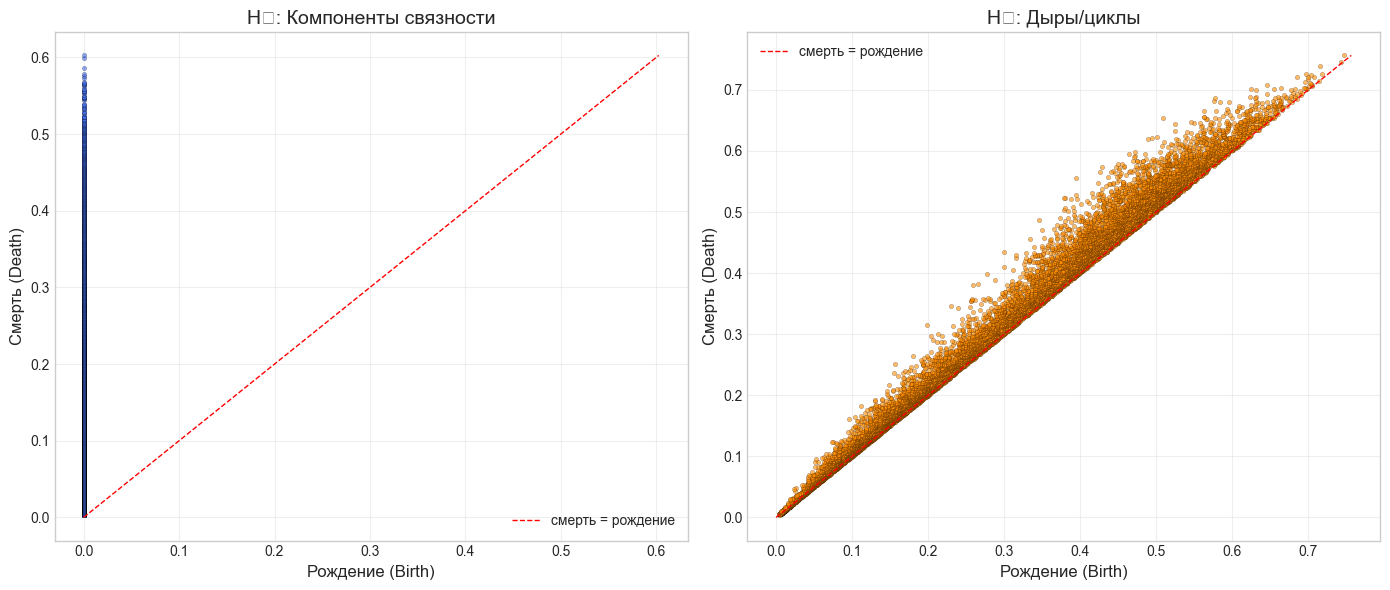

Сохранено: persistence_diagrams.png


In [15]:
h0_finite = h0[np.isfinite(h0[:, 1])]

plt.style.use('seaborn-v0_8-whitegrid')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# H₀
ax1.scatter(h0_finite[:, 0], h0_finite[:, 1], s=10, alpha=0.6,
            color='royalblue', edgecolor='k', linewidth=0.2)
ax1.plot([0, h0_finite[:, 1].max()], [0, h0_finite[:, 1].max()],
         'r--', linewidth=1, label='смерть = рождение')
ax1.set_xlabel('Рождение (Birth)', fontsize=12)
ax1.set_ylabel('Смерть (Death)', fontsize=12)
ax1.set_title('H₀: Компоненты связности', fontsize=14)
ax1.legend(); ax1.grid(True, alpha=0.3)

# H₁
ax2.scatter(h1[:, 0], h1[:, 1], s=10, alpha=0.6,
            color='darkorange', edgecolor='k', linewidth=0.2)
max_val = max(h1[:, 1].max(), h1[:, 0].max())
ax2.plot([0, max_val], [0, max_val], 'r--', linewidth=1, label='смерть = рождение')
ax2.set_xlabel('Рождение (Birth)', fontsize=12)
ax2.set_ylabel('Смерть (Death)', fontsize=12)
ax2.set_title('H₁: Дыры/циклы', fontsize=14)
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('persistence_diagrams.png', dpi=300, bbox_inches='tight')
plt.show()
print("Сохранено: persistence_diagrams.png")

H₀: всего 16395, оставлено 14598
H₁: всего 12788, оставлено 4312


/tmp/ipykernel_250519/4118095150.py:37: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.tight_layout()
/tmp/ipykernel_250519/4118095150.py:37: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/tmp/ipykernel_250519/4118095150.py:37: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.tight_layout()
/tmp/ipykernel_250519/4118095150.py:38: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.savefig('barcodes_akk_filtered.png', dpi=300, bbox_inches='tight')
/tmp/ipykernel_250519/4118095150.py:38: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig('barcodes_akk_filtered.png', dpi=300, bbox_inches='tight')
/tmp/ipykernel_250519/4118095150.py:38: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.savefig('barcodes_akk_filtered.png', dpi=300, bbox_inches='tight')
/home/kuklelik/Jup

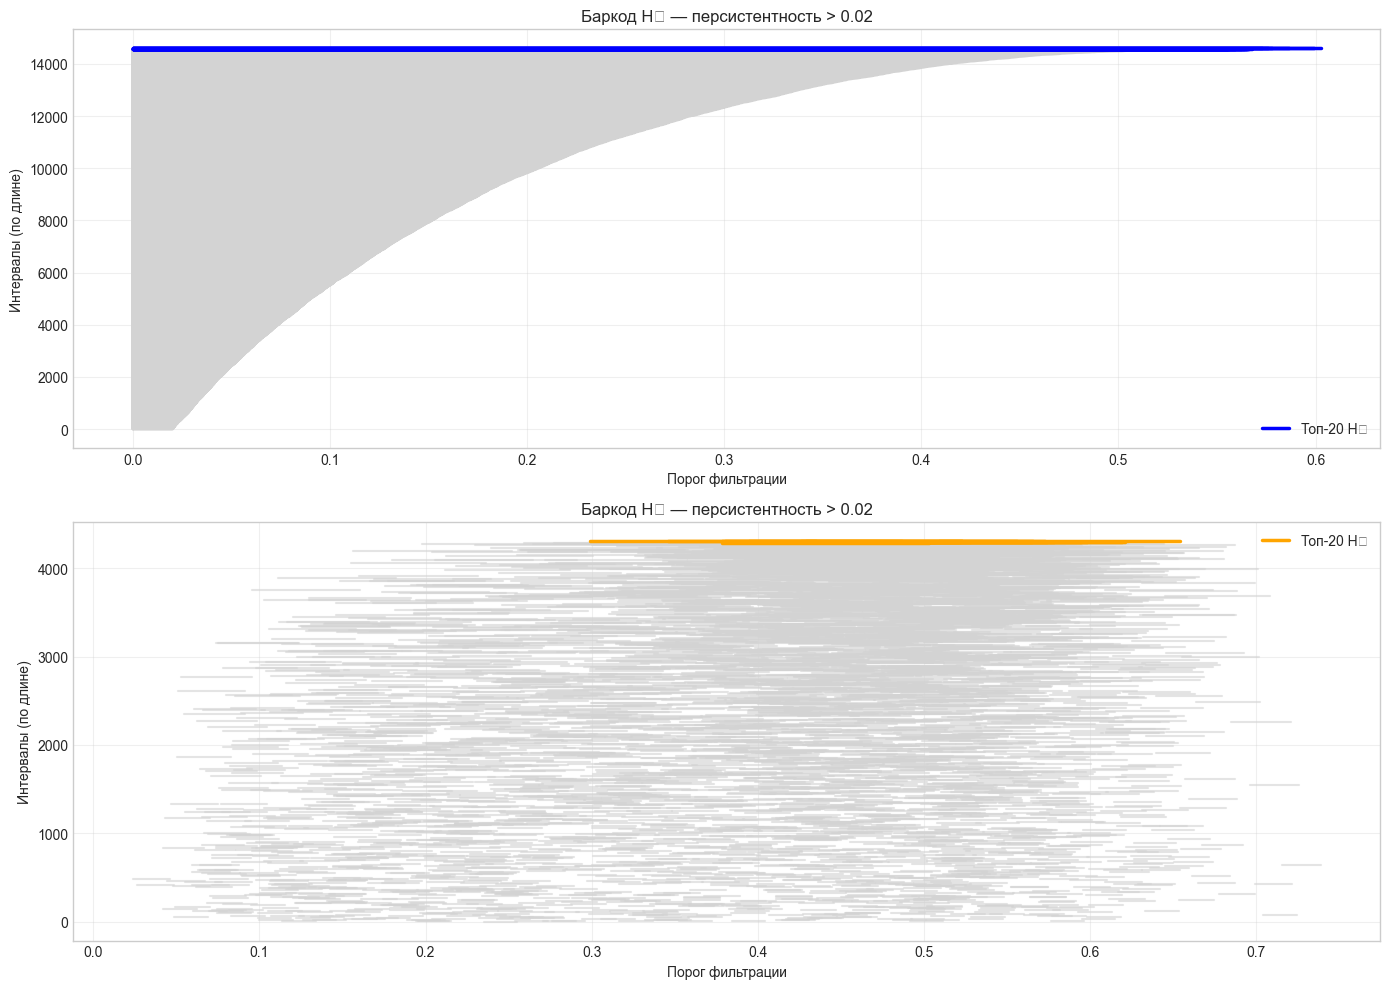

Сохранено: barcodes_akk_filtered.png


In [16]:
min_persistence = 0.02

h0_filtered = h0_finite[h0_finite[:, 1] - h0_finite[:, 0] >= min_persistence]
h1_filtered = h1[h1[:, 1] - h1[:, 0] >= min_persistence]

h0_sorted = h0_filtered[np.argsort(h0_filtered[:, 1] - h0_filtered[:, 0])]
h1_sorted = h1_filtered[np.argsort(h1_filtered[:, 1] - h1_filtered[:, 0])]

print(f"H₀: всего {len(h0_finite)}, оставлено {len(h0_filtered)}")
print(f"H₁: всего {len(h1)}, оставлено {len(h1_filtered)}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))
top_n = 20

# H₀
for i, (b, d) in enumerate(h0_sorted):
    ax1.plot([b, d], [i, i], color='lightgray', linewidth=1.5, alpha=0.6)
for i, (b, d) in enumerate(h0_sorted[-top_n:]):
    idx = len(h0_sorted) - top_n + i
    ax1.plot([b, d], [idx, idx], color='blue', linewidth=2.5,
             label='Топ-20 H₀' if i == 0 else "")
ax1.set_xlabel('Порог фильтрации'); ax1.set_ylabel('Интервалы (по длине)')
ax1.set_title(f'Баркод H₀ — персистентность > {min_persistence}')
ax1.grid(True, alpha=0.3); ax1.legend()

# H₁
for i, (b, d) in enumerate(h1_sorted):
    ax2.plot([b, d], [i, i], color='lightgray', linewidth=1.5, alpha=0.6)
for i, (b, d) in enumerate(h1_sorted[-top_n:]):
    idx = len(h1_sorted) - top_n + i
    ax2.plot([b, d], [idx, idx], color='orange', linewidth=2.5,
             label='Топ-20 H₁' if i == 0 else "")
ax2.set_xlabel('Порог фильтрации'); ax2.set_ylabel('Интервалы (по длине)')
ax2.set_title(f'Баркод H₁ — персистентность > {min_persistence}')
ax2.grid(True, alpha=0.3); ax2.legend()

plt.tight_layout()
plt.savefig('barcodes_akk_filtered.png', dpi=300, bbox_inches='tight')
plt.show()
print("Сохранено: barcodes_akk_filtered.png")

In [17]:
h0_persistence = h0[:, 1] - h0[:, 0]
h1_persistence = h1[:, 1] - h1[:, 0]

top10_h0 = np.argsort(h0_persistence)[-10:][::-1]
top10_h1 = np.argsort(h1_persistence)[-10:][::-1]

print("Топ-10 устойчивых компонент H₀:")
for i, idx in enumerate(top10_h0):
    print(f"{i+1}. Рождение: {h0[idx, 0]:.3f}, Смерть: {h0[idx, 1]:.3f}, Перс: {h0_persistence[idx]:.3f}")

print("\nТоп-10 устойчивых дыр H₁:")
for i, idx in enumerate(top10_h1):
    print(f"{i+1}. Рождение: {h1[idx, 0]:.3f}, Смерть: {h1[idx, 1]:.3f}, Перс: {h1_persistence[idx]:.3f}")

print(f"\nСтатистика H₀: {len(h0)} компонент")
print(f"  Средняя перс: {np.nanmean(h0_persistence):.3f}")
print(f"  Макс. перс: {np.nanmax(h0_persistence):.3f}")

print(f"\nСтатистика H₁: {len(h1)} дыр")
print(f"  Средняя перс: {np.mean(h1_persistence):.3f}")
print(f"  Макс. перс: {np.max(h1_persistence):.3f}")
print(f"\nСоотношение дыры/компоненты: {len(h1)/len(h0):.2f}")

Топ-10 устойчивых компонент H₀:
1. Рождение: 0.000, Смерть: inf, Перс: inf
2. Рождение: 0.000, Смерть: 0.603, Перс: 0.603
3. Рождение: 0.000, Смерть: 0.599, Перс: 0.599
4. Рождение: 0.000, Смерть: 0.587, Перс: 0.587
5. Рождение: 0.000, Смерть: 0.578, Перс: 0.578
6. Рождение: 0.000, Смерть: 0.576, Перс: 0.576
7. Рождение: 0.000, Смерть: 0.573, Перс: 0.573
8. Рождение: 0.000, Смерть: 0.568, Перс: 0.568
9. Рождение: 0.000, Смерть: 0.566, Перс: 0.566
10. Рождение: 0.000, Смерть: 0.566, Перс: 0.566

Топ-10 устойчивых дыр H₁:
1. Рождение: 0.395, Смерть: 0.556, Перс: 0.161
2. Рождение: 0.509, Смерть: 0.654, Перс: 0.145
3. Рождение: 0.429, Смерть: 0.573, Перс: 0.144
4. Рождение: 0.379, Смерть: 0.523, Перс: 0.144
5. Рождение: 0.380, Смерть: 0.523, Перс: 0.143
6. Рождение: 0.346, Смерть: 0.487, Перс: 0.141
7. Рождение: 0.426, Смерть: 0.565, Перс: 0.140
8. Рождение: 0.299, Смерть: 0.435, Перс: 0.136
9. Рождение: 0.387, Смерть: 0.521, Перс: 0.134
10. Рождение: 0.395, Смерть: 0.528, Перс: 0.133

Ст

In [19]:
# Индексы уже приведены к плоскому массиву в Главе 1
unique_hole_words = sorted(set(words[i] for i in indices))

print(f"Всего слов в корпусе: {len(words)}")
print(f"Уникальных слов из дыр: {len(unique_hole_words)}")
print(f"Доля: {len(unique_hole_words)/len(words)*100:.1f}%")

# Для просмотра — первые 30
for w in unique_hole_words[:10]:
    print(f"  - {w}")

Всего слов в корпусе: 16396
Уникальных слов из дыр: 1989
Доля: 12.1%
  - abanr├ómi
  - abatte
  - abba
  - abdanu
  - abdiadda
  - abdikurra
  - abdilisupu
  - abi
  - abiaia
  - abiaya


Загружено 20 дыр
Узлов: 82, Рёбер: 156


/tmp/ipykernel_250519/3993835865.py:33: UserWarning: Glyph 7779 (\N{LATIN SMALL LETTER S WITH DOT BELOW}) missing from font(s) Arial.
  plt.savefig('holes_graph.png', dpi=300, bbox_inches='tight')
/tmp/ipykernel_250519/3993835865.py:33: UserWarning: Glyph 702 (\N{MODIFIER LETTER RIGHT HALF RING}) missing from font(s) Arial.
  plt.savefig('holes_graph.png', dpi=300, bbox_inches='tight')
/home/kuklelik/Jupyter/venv1/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 7779 (\N{LATIN SMALL LETTER S WITH DOT BELOW}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/home/kuklelik/Jupyter/venv1/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 702 (\N{MODIFIER LETTER RIGHT HALF RING}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


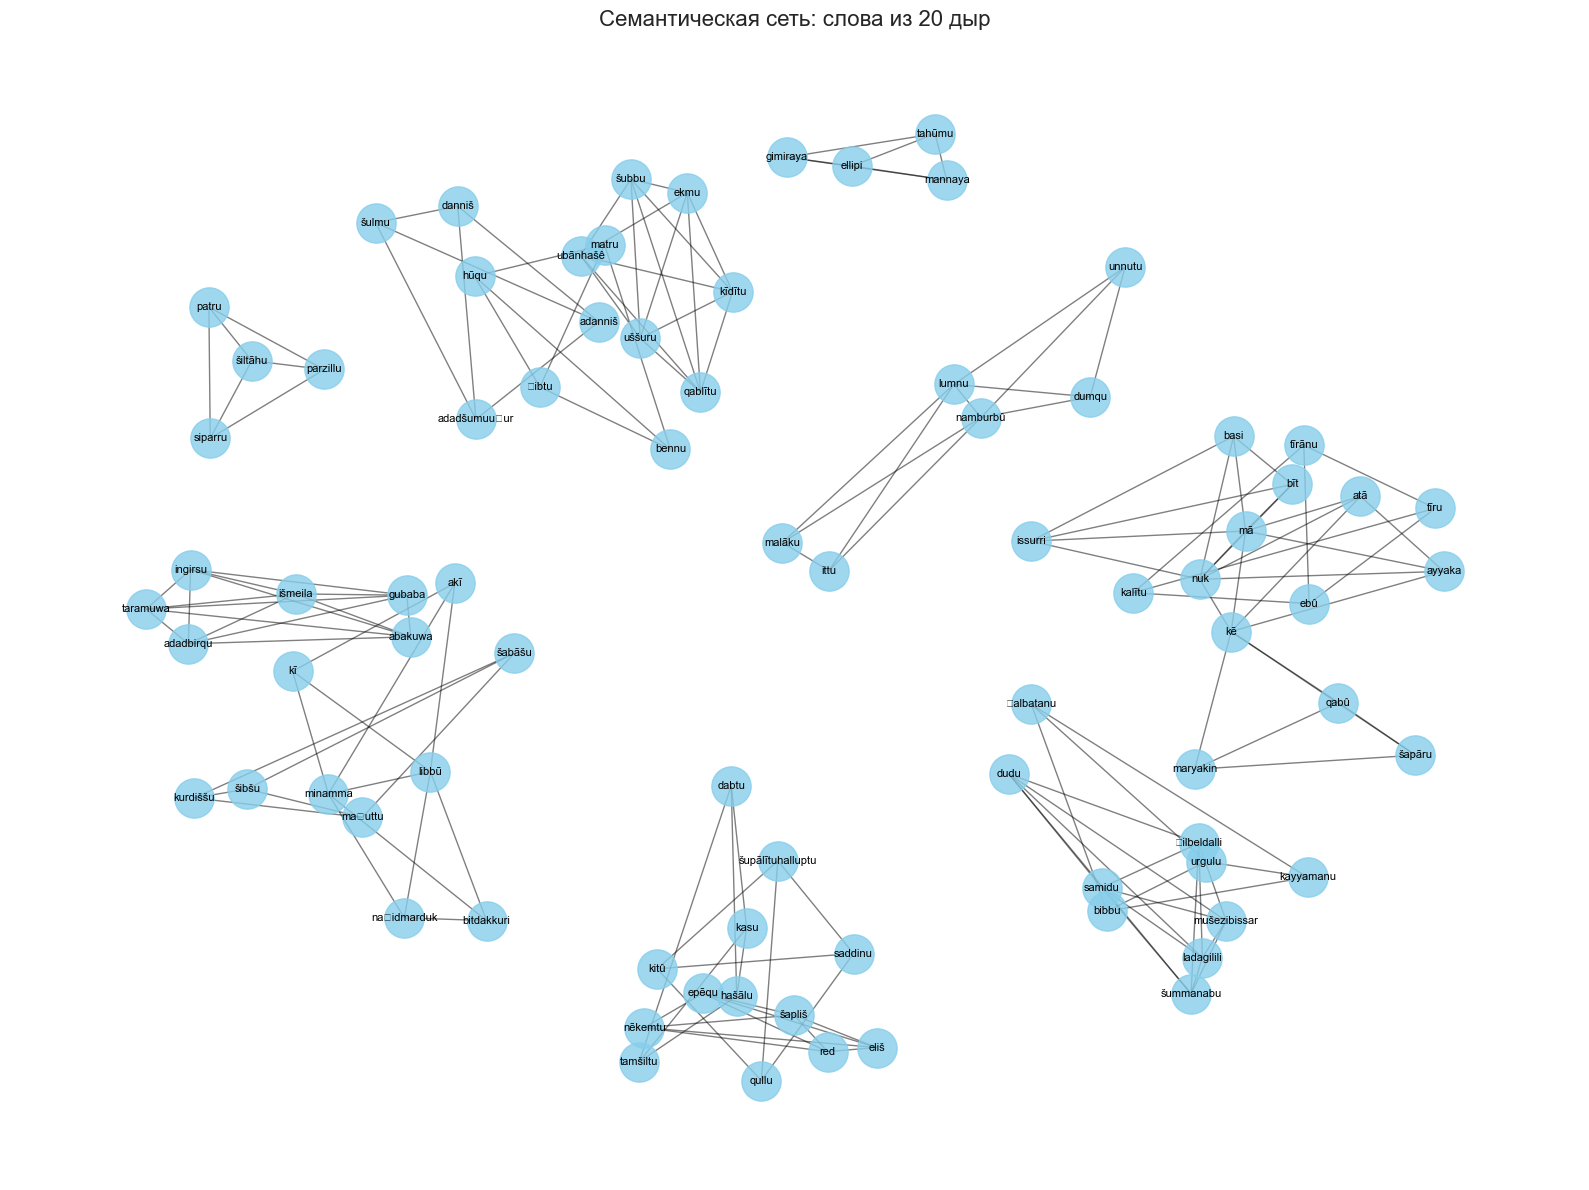

Сохранено: holes_graph.png


In [20]:
# Семантическая сеть: слова из 20 дыр
def load_holes(filename):
    holes = []
    with open(filename, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            if line[0].isdigit() and '. ' in line:
                line = line.split('. ', 1)[1]
            words_in_hole = [w.strip() for w in line.split('|') if w.strip()]
            holes.append(words_in_hole)
    return holes

holes = load_holes('holes_bounds_akk_NEW.txt')
print(f"Загружено {len(holes)} дыр")

G = nx.Graph()
for hole in holes:
    for i, w1 in enumerate(hole):
        for w2 in hole[i+1:]:
            G.add_edge(w1, w2)

print(f"Узлов: {G.number_of_nodes()}, Рёбер: {G.number_of_edges()}")

plt.figure(figsize=(16, 12))
pos = nx.spring_layout(G, seed=42, k=0.5)
nx.draw_networkx_nodes(G, pos, node_size=800, node_color='skyblue', alpha=0.8)
nx.draw_networkx_edges(G, pos, width=1.0, alpha=0.5)
nx.draw_networkx_labels(G, pos, font_size=8)
plt.title("Семантическая сеть: слова из 20 дыр", fontsize=16)
plt.axis('off')
plt.tight_layout()
plt.savefig('holes_graph.png', dpi=300, bbox_inches='tight')
plt.show()
print("Сохранено: holes_graph.png")

/home/kuklelik/Jupyter/venv1/lib/python3.12/site-packages/seaborn/utils.py:61: UserWarning: Glyph 7779 (\N{LATIN SMALL LETTER S WITH DOT BELOW}) missing from font(s) Arial.
  fig.canvas.draw()
/home/kuklelik/Jupyter/venv1/lib/python3.12/site-packages/seaborn/utils.py:61: UserWarning: Glyph 702 (\N{MODIFIER LETTER RIGHT HALF RING}) missing from font(s) Arial.
  fig.canvas.draw()
/home/kuklelik/Jupyter/venv1/lib/python3.12/site-packages/seaborn/utils.py:61: UserWarning: Glyph 7789 (\N{LATIN SMALL LETTER T WITH DOT BELOW}) missing from font(s) Arial.
  fig.canvas.draw()
/tmp/ipykernel_250519/2520996619.py:18: UserWarning: Glyph 7779 (\N{LATIN SMALL LETTER S WITH DOT BELOW}) missing from font(s) Arial.
  plt.tight_layout()
/tmp/ipykernel_250519/2520996619.py:18: UserWarning: Glyph 702 (\N{MODIFIER LETTER RIGHT HALF RING}) missing from font(s) Arial.
  plt.tight_layout()
/tmp/ipykernel_250519/2520996619.py:18: UserWarning: Glyph 7789 (\N{LATIN SMALL LETTER T WITH DOT BELOW}) missing from fo

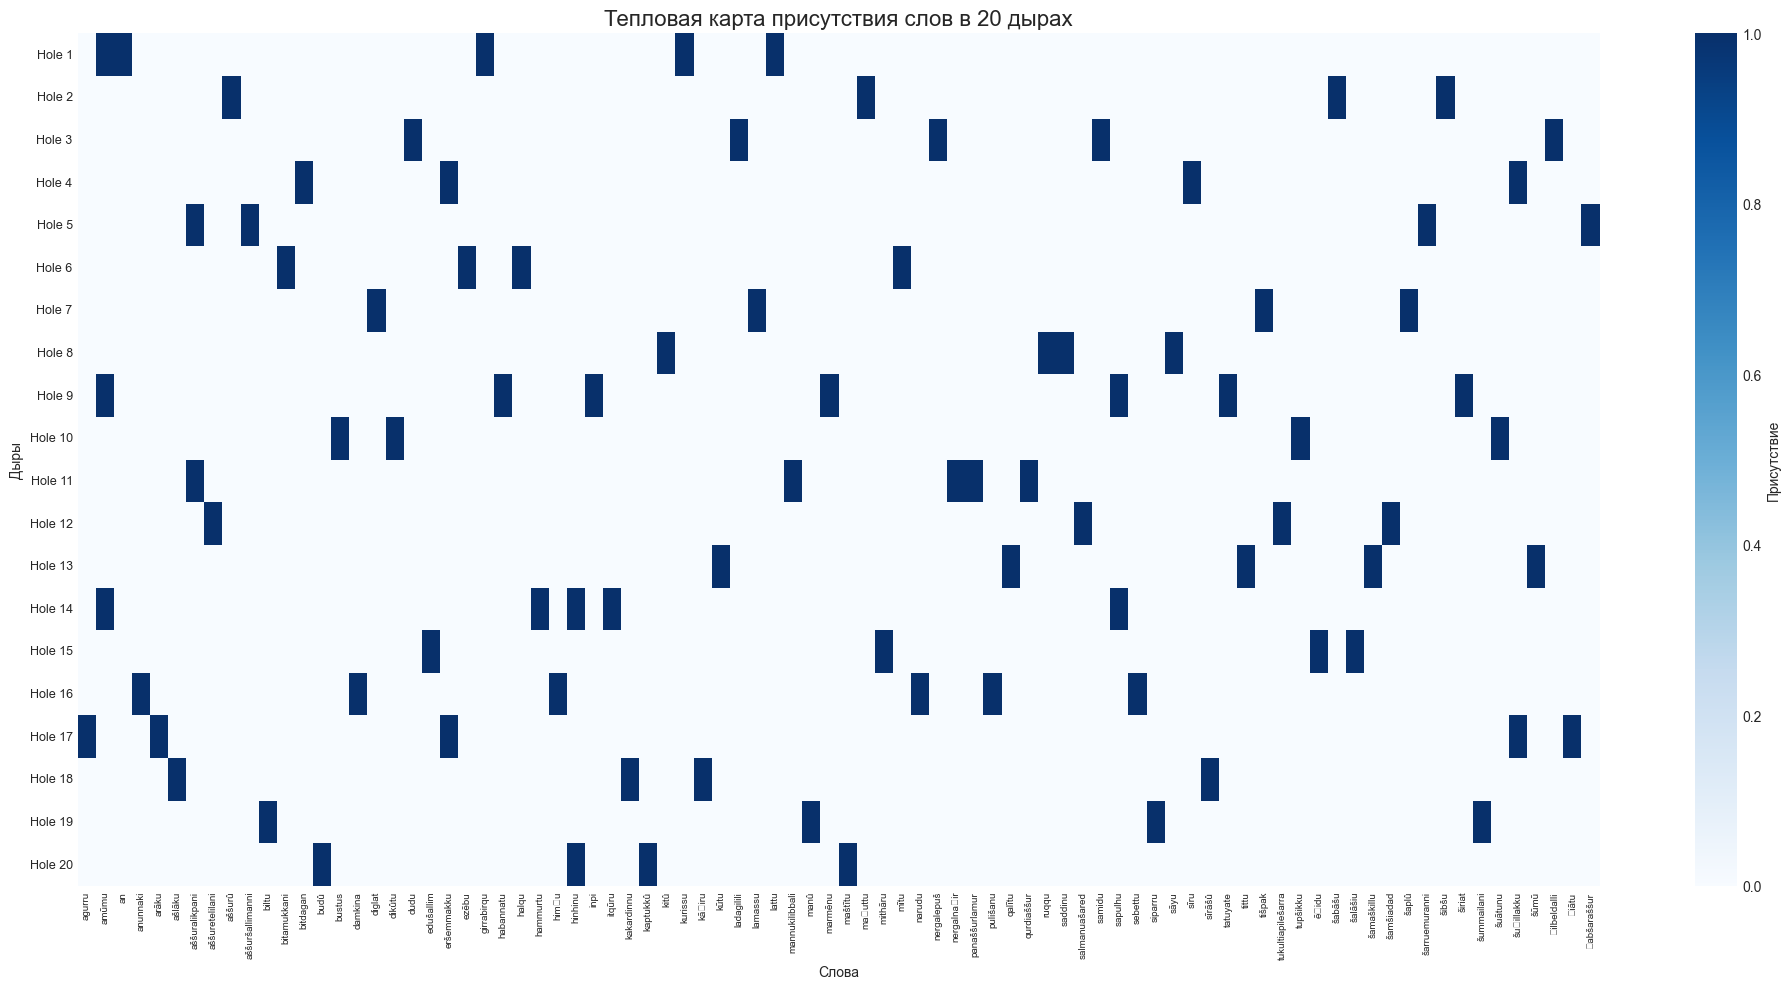

Сохранено: holes_heatmap.png
Сохранено: holes_matrix.csv


In [32]:
# Тепловая карта присутствия слов в 20 дырах
all_words = sorted(set(w for hole in holes for w in hole))
matrix = np.zeros((len(holes), len(all_words)), dtype=int)

for i, hole in enumerate(holes):
    for word in hole:
        j = all_words.index(word)
        matrix[i, j] = 1

plt.figure(figsize=(20, 10))
sns.heatmap(matrix,
            xticklabels=all_words,
            yticklabels=[f"Hole {i+1}" for i in range(len(holes))],
            cmap='Blues', cbar_kws={'label': 'Присутствие'})
plt.title("Тепловая карта присутствия слов в 20 дырах", fontsize=16)
plt.xlabel("Слова"); plt.ylabel("Дыры")
plt.xticks(rotation=90, fontsize=7); plt.yticks(fontsize=9)
plt.tight_layout()
plt.savefig('holes_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
print("Сохранено: holes_heatmap.png")

# Сохранение матрицы в CSV
df = pd.DataFrame(matrix,
                  index=[f"Hole_{i+1}" for i in range(len(holes))],
                  columns=all_words)
df.to_csv('holes_matrix.csv')
print("Сохранено: holes_matrix.csv")

In [22]:
import plotly.graph_objects as go
import random
from sklearn.metrics.pairwise import cosine_similarity

# Выборка слов (можно изменить на 4000, но будет тяжелее для браузера)
SAMPLE_SIZE = 100
random.seed(42)
sample_indices = random.sample(range(len(words)), SAMPLE_SIZE)
sample_words = [words[i] for i in sample_indices]
sample_vectors = np.array([npz[w] for w in sample_words])

# Слова из дыр (для подсветки)
holes_words = set(words[i] for i in indices)

# Построение графа по косинусному сходству
threshold = 0.3
G_plot = nx.Graph()
G_plot.add_nodes_from(sample_words)

sim = cosine_similarity(sample_vectors)
for i in range(len(sample_words)):
    for j in range(i+1, len(sample_words)):
        if sim[i, j] > threshold:
            G_plot.add_edge(sample_words[i], sample_words[j], weight=float(sim[i, j]))

print(f"Узлов: {G_plot.number_of_nodes()}, Рёбер: {G_plot.number_of_edges()}")

# Раскладка
pos = nx.spring_layout(G_plot, seed=42, k=0.3, iterations=50)

# Подготовка данных для Plotly
edge_x, edge_y = [], []
for u, v in G_plot.edges():
    x0, y0 = pos[u]; x1, y1 = pos[v]
    edge_x.extend([x0, x1, None]); edge_y.extend([y0, y1, None])

node_x, node_y, node_text, node_color, node_size = [], [], [], [], []
for node in G_plot.nodes():
    x, y = pos[node]
    node_x.append(x); node_y.append(y); node_text.append(node)
    if node in holes_words:
        node_color.append('orange'); node_size.append(15)
    else:
        node_color.append('lightblue'); node_size.append(8)

fig = go.Figure()
fig.add_trace(go.Scatter(x=edge_x, y=edge_y, mode='lines',
                         line=dict(width=1, color='lightgrey'),
                         hoverinfo='none', showlegend=False))
fig.add_trace(go.Scatter(x=node_x, y=node_y, mode='markers+text',
                         marker=dict(size=node_size, color=node_color,
                                     line=dict(width=1, color='DarkSlateGrey')),
                         text=node_text, textposition="top center",
                         textfont=dict(size=8), hoverinfo='text', showlegend=False))
fig.update_layout(title=f'Семантический граф ({SAMPLE_SIZE} слов)',
                  showlegend=False, hovermode='closest',
                  xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
                  yaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
                  width=1200, height=800, template='plotly_white')

fig.write_html('semantic_graph_plotly.html')
print("Сохранено: semantic_graph_plotly.html")

Узлов: 100, Рёбер: 2980
Сохранено: semantic_graph_plotly.html


**Теперь анализ для новоассирийского**

In [24]:
h0 = np.load('h0_results_ass.npy') 
h1 = np.load('h1_results_ass.npy') 

npz = np.load('ass_embeddings.npz', allow_pickle=True)
words = list(npz.keys())

indices_raw = np.load('akk_word_holes_ass.npy')

# приводим индексы к плоскому массиву
indices = indices_raw.flatten() if indices_raw.ndim == 2 else indices_raw

with open('holes_bounds_ass_BEST.txt', 'r', encoding='utf-8') as f:
    hole_lines = [line.strip() for line in f if line.strip()]

print(f"Загружено: H₀={len(h0)}, H₁={len(h1)}, слов={len(words)}, дыр (текст)={len(hole_lines)}")

Загружено: H₀=12294, H₁=8412, слов=12294, дыр (текст)=20


/tmp/ipykernel_250519/2246455435.py:26: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.tight_layout()
/tmp/ipykernel_250519/2246455435.py:26: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.tight_layout()
/tmp/ipykernel_250519/2246455435.py:27: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.savefig('persistence_diagrams_ass.png', dpi=300, bbox_inches='tight')
/tmp/ipykernel_250519/2246455435.py:27: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.savefig('persistence_diagrams_ass.png', dpi=300, bbox_inches='tight')
/home/kuklelik/Jupyter/venv1/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/home/kuklelik/Jupyter/venv1/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font

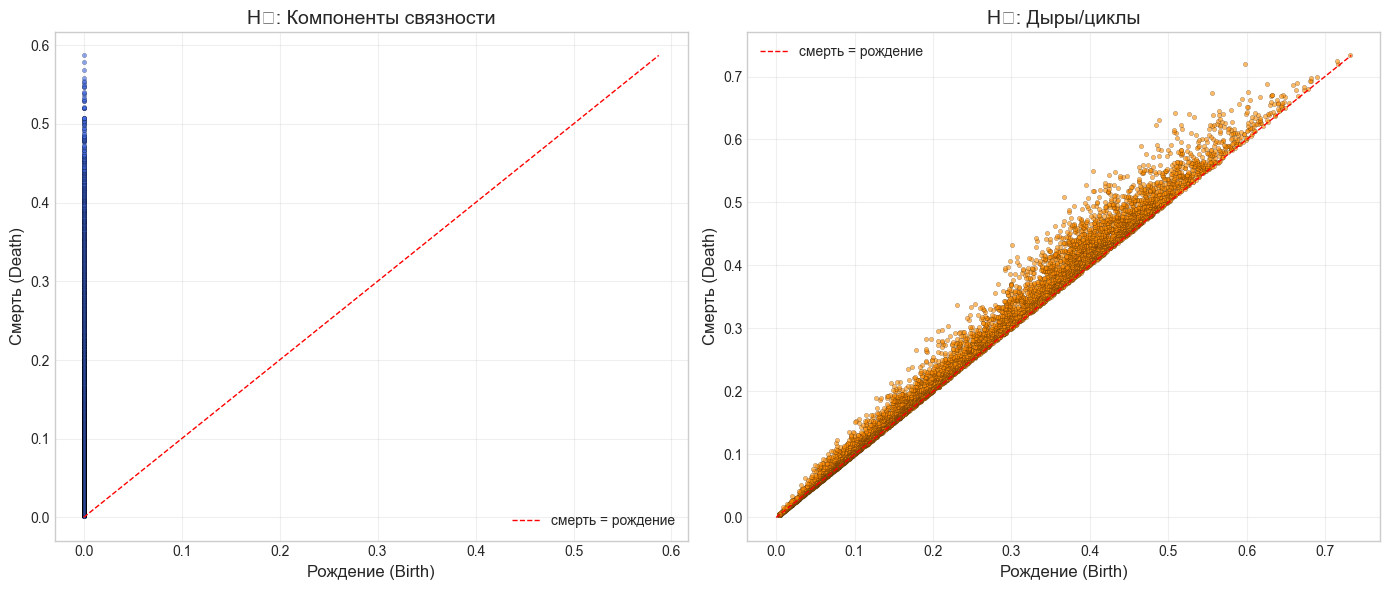

Сохранено: persistence_diagrams_ass.png


In [25]:
h0_finite = h0[np.isfinite(h0[:, 1])]

plt.style.use('seaborn-v0_8-whitegrid')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# H₀
ax1.scatter(h0_finite[:, 0], h0_finite[:, 1], s=10, alpha=0.6,
            color='royalblue', edgecolor='k', linewidth=0.2)
ax1.plot([0, h0_finite[:, 1].max()], [0, h0_finite[:, 1].max()],
         'r--', linewidth=1, label='смерть = рождение')
ax1.set_xlabel('Рождение (Birth)', fontsize=12)
ax1.set_ylabel('Смерть (Death)', fontsize=12)
ax1.set_title('H₀: Компоненты связности', fontsize=14)
ax1.legend(); ax1.grid(True, alpha=0.3)

# H₁
ax2.scatter(h1[:, 0], h1[:, 1], s=10, alpha=0.6,
            color='darkorange', edgecolor='k', linewidth=0.2)
max_val = max(h1[:, 1].max(), h1[:, 0].max())
ax2.plot([0, max_val], [0, max_val], 'r--', linewidth=1, label='смерть = рождение')
ax2.set_xlabel('Рождение (Birth)', fontsize=12)
ax2.set_ylabel('Смерть (Death)', fontsize=12)
ax2.set_title('H₁: Дыры/циклы', fontsize=14)
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('persistence_diagrams_ass.png', dpi=300, bbox_inches='tight')
plt.show()
print("Сохранено: persistence_diagrams_ass.png")

H₀: всего 12293, оставлено 11041
H₁: всего 8412, оставлено 2276


/tmp/ipykernel_250519/3656298225.py:37: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.tight_layout()
/tmp/ipykernel_250519/3656298225.py:37: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/tmp/ipykernel_250519/3656298225.py:37: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.tight_layout()
/tmp/ipykernel_250519/3656298225.py:38: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.savefig('barcodes_akk_filtered_ass.png', dpi=300, bbox_inches='tight')
/tmp/ipykernel_250519/3656298225.py:38: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig('barcodes_akk_filtered_ass.png', dpi=300, bbox_inches='tight')
/tmp/ipykernel_250519/3656298225.py:38: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.savefig('barcodes_akk_filtered_ass.png', dpi=300, bbox_inches='tight')
/home/

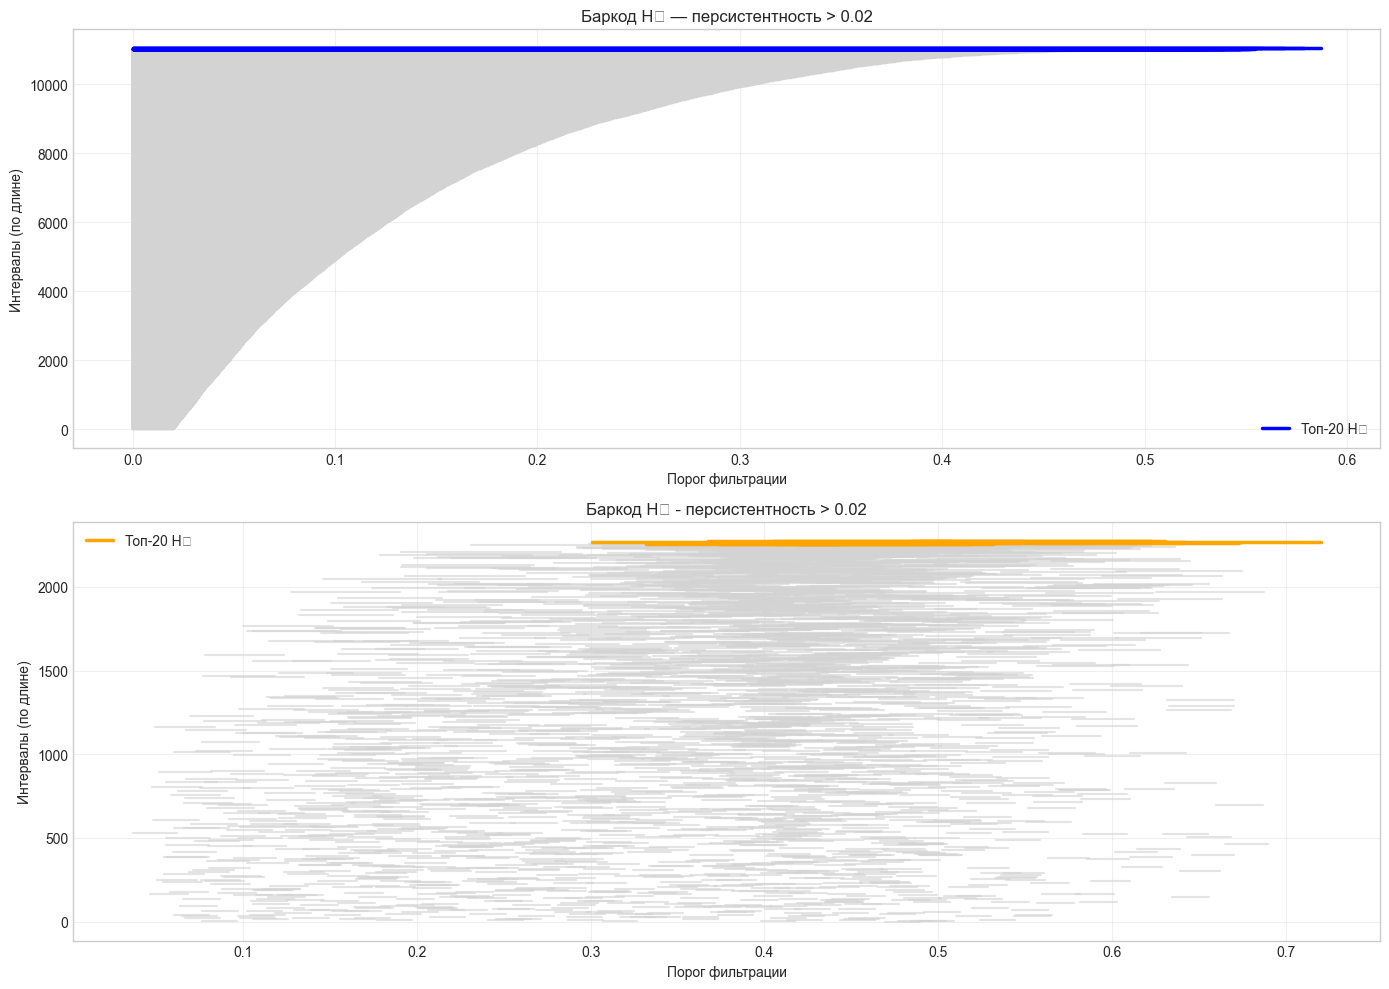

Сохранено: barcodes_akk_filtered_ass.png


In [26]:
min_persistence = 0.02

h0_filtered = h0_finite[h0_finite[:, 1] - h0_finite[:, 0] >= min_persistence]
h1_filtered = h1[h1[:, 1] - h1[:, 0] >= min_persistence]

h0_sorted = h0_filtered[np.argsort(h0_filtered[:, 1] - h0_filtered[:, 0])]
h1_sorted = h1_filtered[np.argsort(h1_filtered[:, 1] - h1_filtered[:, 0])]

print(f"H₀: всего {len(h0_finite)}, оставлено {len(h0_filtered)}")
print(f"H₁: всего {len(h1)}, оставлено {len(h1_filtered)}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))
top_n = 20

# H₀
for i, (b, d) in enumerate(h0_sorted):
    ax1.plot([b, d], [i, i], color='lightgray', linewidth=1.5, alpha=0.6)
for i, (b, d) in enumerate(h0_sorted[-top_n:]):
    idx = len(h0_sorted) - top_n + i
    ax1.plot([b, d], [idx, idx], color='blue', linewidth=2.5,
             label='Топ-20 H₀' if i == 0 else "")
ax1.set_xlabel('Порог фильтрации'); ax1.set_ylabel('Интервалы (по длине)')
ax1.set_title(f'Баркод H₀ — персистентность > {min_persistence}')
ax1.grid(True, alpha=0.3); ax1.legend()

# H₁
for i, (b, d) in enumerate(h1_sorted):
    ax2.plot([b, d], [i, i], color='lightgray', linewidth=1.5, alpha=0.6)
for i, (b, d) in enumerate(h1_sorted[-top_n:]):
    idx = len(h1_sorted) - top_n + i
    ax2.plot([b, d], [idx, idx], color='orange', linewidth=2.5,
             label='Топ-20 H₁' if i == 0 else "")
ax2.set_xlabel('Порог фильтрации'); ax2.set_ylabel('Интервалы (по длине)')
ax2.set_title(f'Баркод H₁ - персистентность > {min_persistence}')
ax2.grid(True, alpha=0.3); ax2.legend()

plt.tight_layout()
plt.savefig('barcodes_akk_filtered_ass.png', dpi=300, bbox_inches='tight')
plt.show()
print("Сохранено: barcodes_akk_filtered_ass.png")

In [27]:
h0_persistence = h0[:, 1] - h0[:, 0]
h1_persistence = h1[:, 1] - h1[:, 0]

top10_h0 = np.argsort(h0_persistence)[-10:][::-1]
top10_h1 = np.argsort(h1_persistence)[-10:][::-1]

print("Топ-10 устойчивых компонент H₀:")
for i, idx in enumerate(top10_h0):
    print(f"{i+1}. Рождение: {h0[idx, 0]:.3f}, Смерть: {h0[idx, 1]:.3f}, Перс: {h0_persistence[idx]:.3f}")

print("\nТоп-10 устойчивых дыр H₁:")
for i, idx in enumerate(top10_h1):
    print(f"{i+1}. Рождение: {h1[idx, 0]:.3f}, Смерть: {h1[idx, 1]:.3f}, Перс: {h1_persistence[idx]:.3f}")

print(f"\nСтатистика H₀: {len(h0)} компонент")
print(f"  Средняя перс: {np.nanmean(h0_persistence):.3f}")
print(f"  Макс. перс: {np.nanmax(h0_persistence):.3f}")

print(f"\nСтатистика H₁: {len(h1)} дыр")
print(f"  Средняя перс: {np.mean(h1_persistence):.3f}")
print(f"  Макс. перс: {np.max(h1_persistence):.3f}")
print(f"\nСоотношение дыры/компоненты: {len(h1)/len(h0):.2f}")

Топ-10 устойчивых компонент H₀:
1. Рождение: 0.000, Смерть: inf, Перс: inf
2. Рождение: 0.000, Смерть: 0.587, Перс: 0.587
3. Рождение: 0.000, Смерть: 0.579, Перс: 0.579
4. Рождение: 0.000, Смерть: 0.569, Перс: 0.569
5. Рождение: 0.000, Смерть: 0.558, Перс: 0.558
6. Рождение: 0.000, Смерть: 0.554, Перс: 0.554
7. Рождение: 0.000, Смерть: 0.553, Перс: 0.553
8. Рождение: 0.000, Смерть: 0.551, Перс: 0.551
9. Рождение: 0.000, Смерть: 0.548, Перс: 0.548
10. Рождение: 0.000, Смерть: 0.547, Перс: 0.547

Топ-10 устойчивых дыр H₁:
1. Рождение: 0.405, Смерть: 0.550, Перс: 0.145
2. Рождение: 0.489, Смерть: 0.631, Перс: 0.142
3. Рождение: 0.368, Смерть: 0.508, Перс: 0.140
4. Рождение: 0.484, Смерть: 0.622, Перс: 0.138
5. Рождение: 0.508, Смерть: 0.642, Перс: 0.134
6. Рождение: 0.395, Смерть: 0.528, Перс: 0.133
7. Рождение: 0.301, Смерть: 0.433, Перс: 0.132
8. Рождение: 0.466, Смерть: 0.590, Перс: 0.124
9. Рождение: 0.597, Смерть: 0.720, Перс: 0.123
10. Рождение: 0.424, Смерть: 0.544, Перс: 0.120

Ст

Загружено 20 дыр
Узлов: 84, Рёбер: 166


/tmp/ipykernel_250519/3329208191.py:34: UserWarning: Glyph 702 (\N{MODIFIER LETTER RIGHT HALF RING}) missing from font(s) Arial.
  plt.savefig('holes_graph_ass.png', dpi=300, bbox_inches='tight')
/tmp/ipykernel_250519/3329208191.py:34: UserWarning: Glyph 7779 (\N{LATIN SMALL LETTER S WITH DOT BELOW}) missing from font(s) Arial.
  plt.savefig('holes_graph_ass.png', dpi=300, bbox_inches='tight')
/tmp/ipykernel_250519/3329208191.py:34: UserWarning: Glyph 7789 (\N{LATIN SMALL LETTER T WITH DOT BELOW}) missing from font(s) Arial.
  plt.savefig('holes_graph_ass.png', dpi=300, bbox_inches='tight')
/home/kuklelik/Jupyter/venv1/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 702 (\N{MODIFIER LETTER RIGHT HALF RING}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/home/kuklelik/Jupyter/venv1/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 7779 (\N{LATIN SMALL LETTER S WITH DOT BELOW}) missing from font(s) Aria

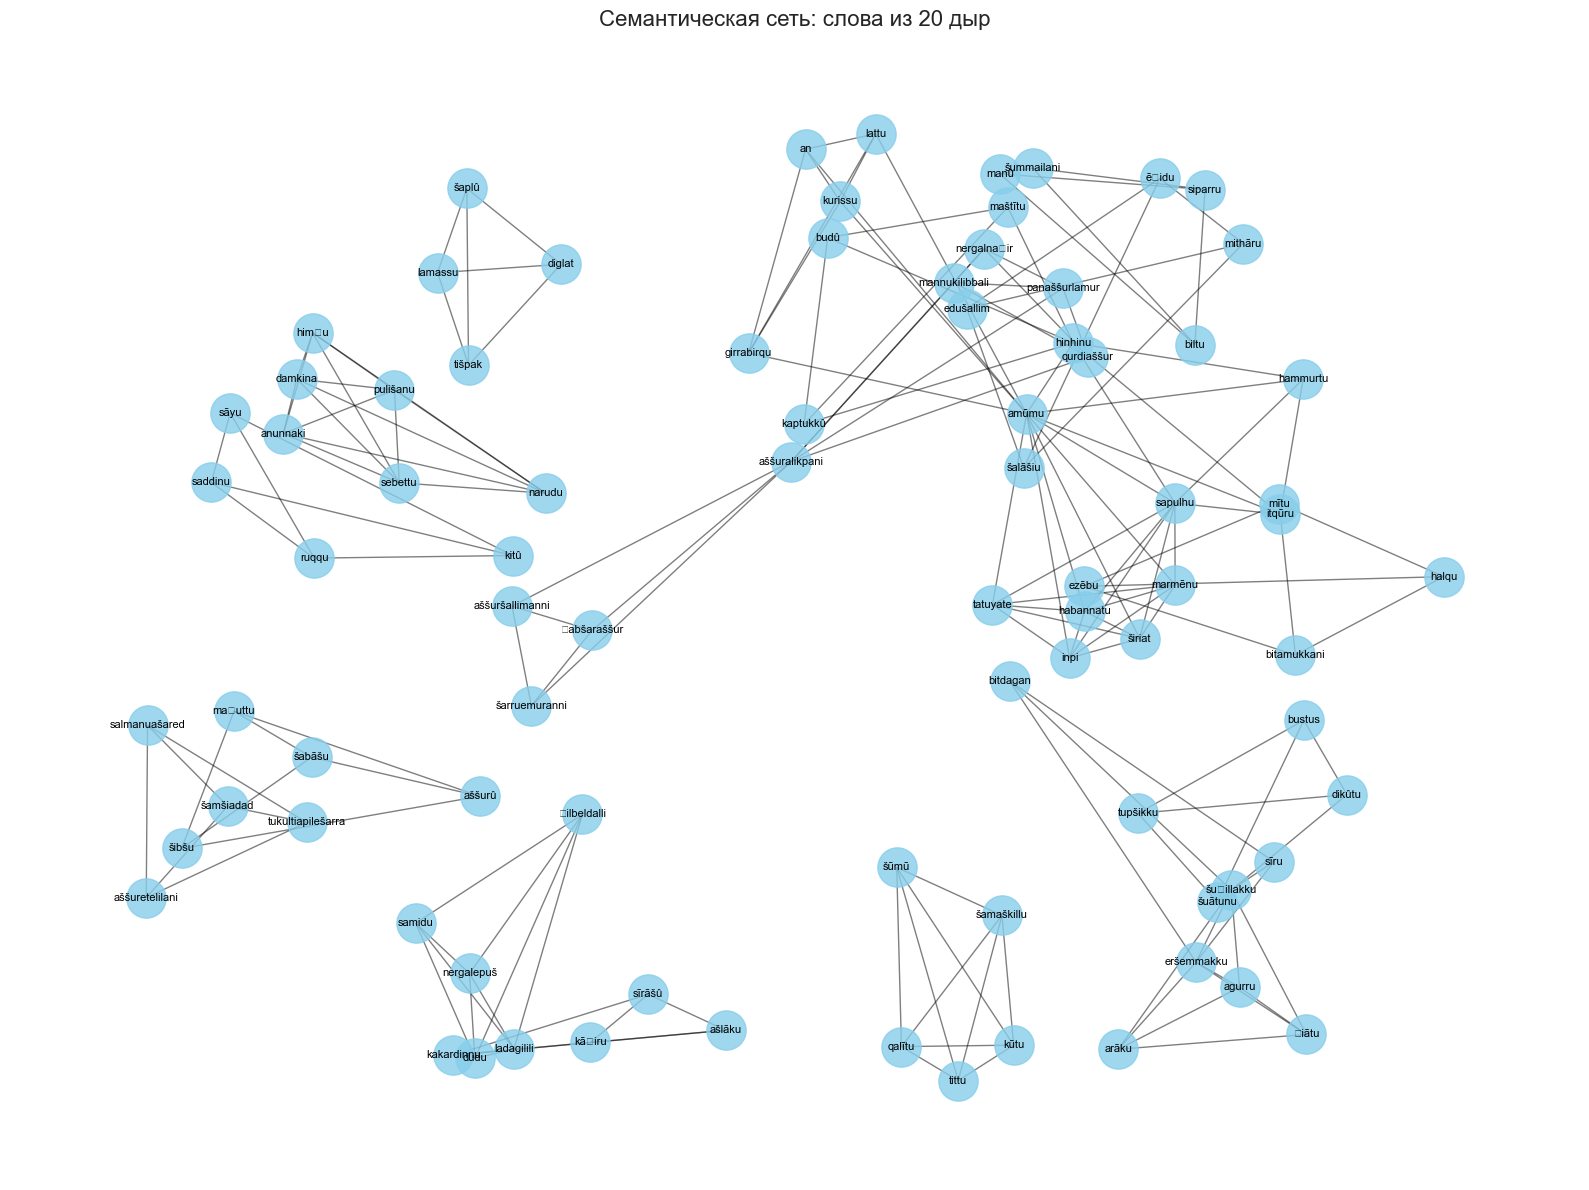

Сохранено: holes_graph_ass.png


In [28]:
# Семантическая сеть: слова из 20 дыр
def load_holes(filename):
    holes = []
    with open(filename, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            if line[0].isdigit() and '. ' in line:
                line = line.split('. ', 1)[1]
            words_in_hole = [w.strip() for w in line.split('|') if w.strip()]
            holes.append(words_in_hole)
    return holes

holes = load_holes('holes_bounds_ass_BEST.txt')
print(f"Загружено {len(holes)} дыр")

G = nx.Graph()
for hole in holes:
    for i, w1 in enumerate(hole):
        for w2 in hole[i+1:]:
            G.add_edge(w1, w2)

print(f"Узлов: {G.number_of_nodes()}, Рёбер: {G.number_of_edges()}")

plt.figure(figsize=(16, 12))
pos = nx.spring_layout(G, seed=42, k=0.5)
nx.draw_networkx_nodes(G, pos, node_size=800, node_color='skyblue', alpha=0.8)
nx.draw_networkx_edges(G, pos, width=1.0, alpha=0.5)
nx.draw_networkx_labels(G, pos, font_size=8)
plt.title("Семантическая сеть: слова из 20 дыр", fontsize=16)
plt.axis('off')
plt.tight_layout()
plt.savefig('holes_graph_ass.png', dpi=300, bbox_inches='tight')
plt.show()
print("Сохранено: holes_graph_ass.png")

/home/kuklelik/Jupyter/venv1/lib/python3.12/site-packages/seaborn/utils.py:61: UserWarning: Glyph 7779 (\N{LATIN SMALL LETTER S WITH DOT BELOW}) missing from font(s) Arial.
  fig.canvas.draw()
/home/kuklelik/Jupyter/venv1/lib/python3.12/site-packages/seaborn/utils.py:61: UserWarning: Glyph 702 (\N{MODIFIER LETTER RIGHT HALF RING}) missing from font(s) Arial.
  fig.canvas.draw()
/home/kuklelik/Jupyter/venv1/lib/python3.12/site-packages/seaborn/utils.py:61: UserWarning: Glyph 7789 (\N{LATIN SMALL LETTER T WITH DOT BELOW}) missing from font(s) Arial.
  fig.canvas.draw()
/tmp/ipykernel_250519/4080867334.py:18: UserWarning: Glyph 7779 (\N{LATIN SMALL LETTER S WITH DOT BELOW}) missing from font(s) Arial.
  plt.tight_layout()
/tmp/ipykernel_250519/4080867334.py:18: UserWarning: Glyph 702 (\N{MODIFIER LETTER RIGHT HALF RING}) missing from font(s) Arial.
  plt.tight_layout()
/tmp/ipykernel_250519/4080867334.py:18: UserWarning: Glyph 7789 (\N{LATIN SMALL LETTER T WITH DOT BELOW}) missing from fo

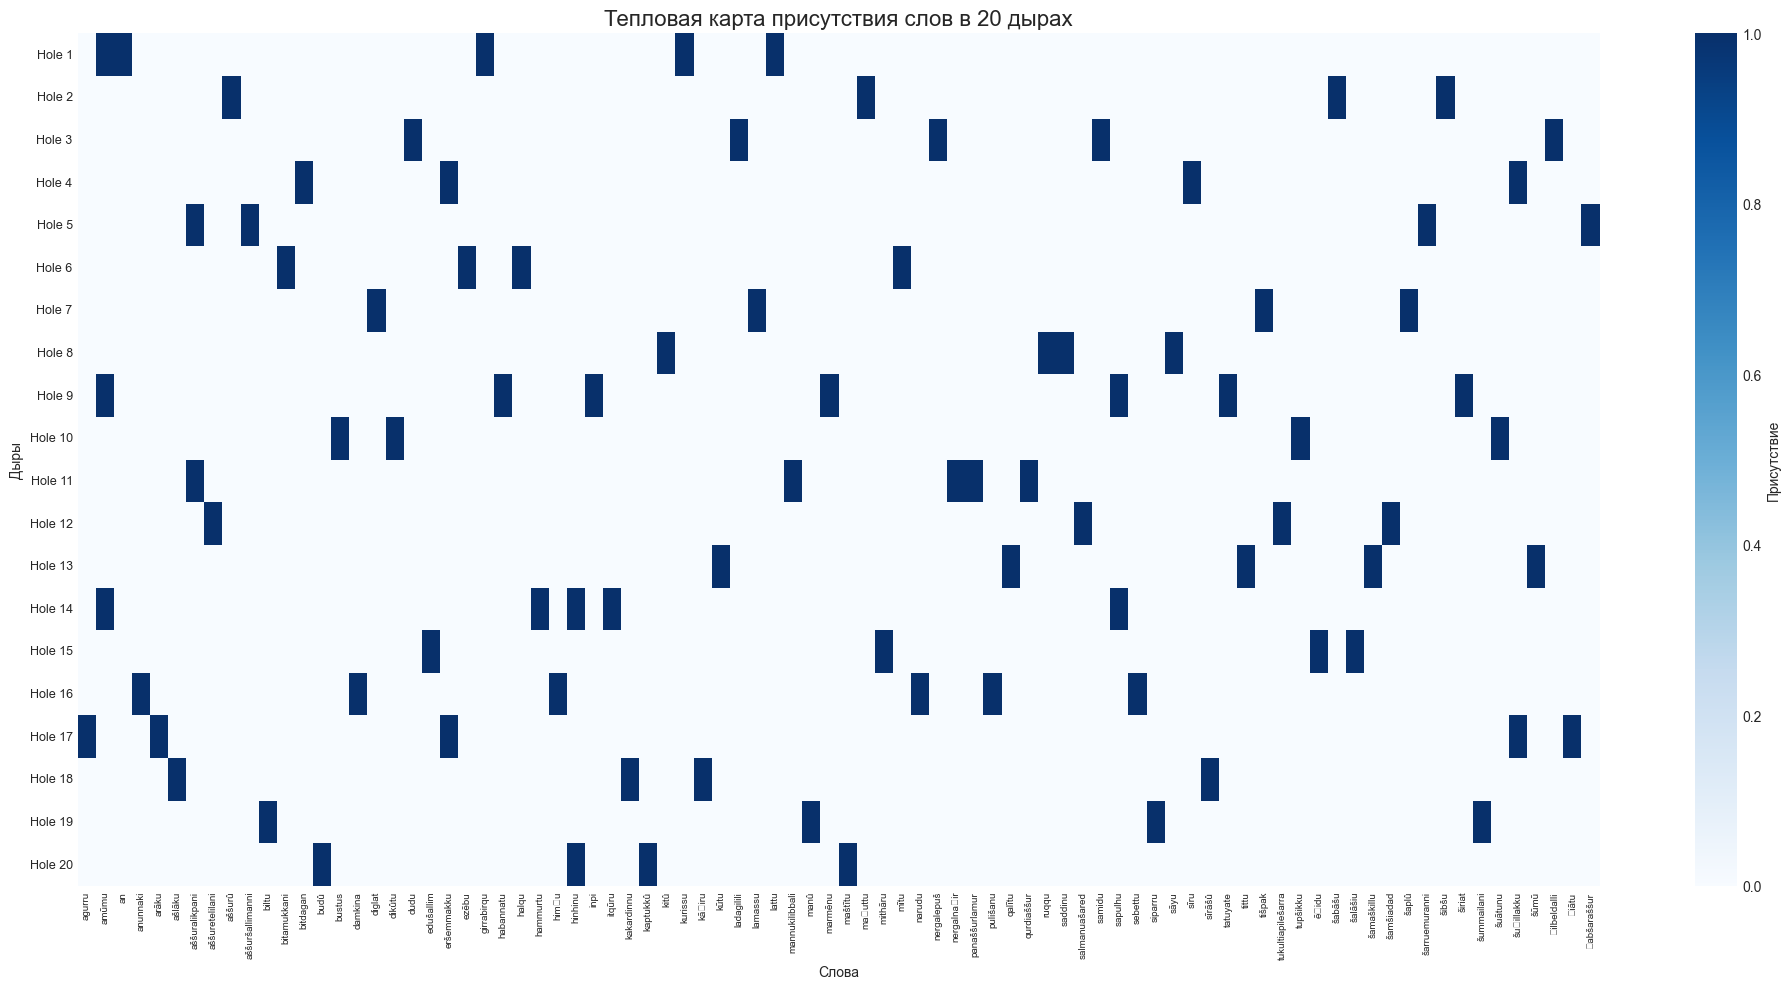

Сохранено: holes_heatmap_ass.png
Сохранено: holes_matrix_ass.csv


In [29]:
# Тепловая карта присутствия слов в 20 дырах
all_words = sorted(set(w for hole in holes for w in hole))
matrix = np.zeros((len(holes), len(all_words)), dtype=int)

for i, hole in enumerate(holes):
    for word in hole:
        j = all_words.index(word)
        matrix[i, j] = 1

plt.figure(figsize=(20, 10))
sns.heatmap(matrix,
            xticklabels=all_words,
            yticklabels=[f"Hole {i+1}" for i in range(len(holes))],
            cmap='Blues', cbar_kws={'label': 'Присутствие'})
plt.title("Тепловая карта присутствия слов в 20 дырах", fontsize=16)
plt.xlabel("Слова"); plt.ylabel("Дыры")
plt.xticks(rotation=90, fontsize=7); plt.yticks(fontsize=9)
plt.tight_layout()
plt.savefig('holes_heatmap_ass.png', dpi=300, bbox_inches='tight')
plt.show()
print("Сохранено: holes_heatmap_ass.png")

# Сохранение матрицы в CSV
df = pd.DataFrame(matrix,
                  index=[f"Hole_{i+1}" for i in range(len(holes))],
                  columns=all_words)
df.to_csv('holes_matrix_ass.csv')
print("Сохранено: holes_matrix_ass.csv")

In [30]:
import plotly.graph_objects as go
import random
from sklearn.metrics.pairwise import cosine_similarity

# Выборка слов (можно изменить на 4000, но будет тяжелее для браузера)
SAMPLE_SIZE = 100
random.seed(42)
sample_indices = random.sample(range(len(words)), SAMPLE_SIZE)
sample_words = [words[i] for i in sample_indices]
sample_vectors = np.array([npz[w] for w in sample_words])

# Слова из дыр (для подсветки)
holes_words = set(words[i] for i in indices)

# Построение графа по косинусному сходству
threshold = 0.3
G_plot = nx.Graph()
G_plot.add_nodes_from(sample_words)

sim = cosine_similarity(sample_vectors)
for i in range(len(sample_words)):
    for j in range(i+1, len(sample_words)):
        if sim[i, j] > threshold:
            G_plot.add_edge(sample_words[i], sample_words[j], weight=float(sim[i, j]))

print(f"Узлов: {G_plot.number_of_nodes()}, Рёбер: {G_plot.number_of_edges()}")

# Раскладка
pos = nx.spring_layout(G_plot, seed=42, k=0.3, iterations=50)

# Подготовка данных для Plotly
edge_x, edge_y = [], []
for u, v in G_plot.edges():
    x0, y0 = pos[u]; x1, y1 = pos[v]
    edge_x.extend([x0, x1, None]); edge_y.extend([y0, y1, None])

node_x, node_y, node_text, node_color, node_size = [], [], [], [], []
for node in G_plot.nodes():
    x, y = pos[node]
    node_x.append(x); node_y.append(y); node_text.append(node)
    if node in holes_words:
        node_color.append('orange'); node_size.append(15)
    else:
        node_color.append('lightblue'); node_size.append(8)

fig = go.Figure()
fig.add_trace(go.Scatter(x=edge_x, y=edge_y, mode='lines',
                         line=dict(width=1, color='lightgrey'),
                         hoverinfo='none', showlegend=False))
fig.add_trace(go.Scatter(x=node_x, y=node_y, mode='markers+text',
                         marker=dict(size=node_size, color=node_color,
                                     line=dict(width=1, color='DarkSlateGrey')),
                         text=node_text, textposition="top center",
                         textfont=dict(size=8), hoverinfo='text', showlegend=False))
fig.update_layout(title=f'Семантический граф ({SAMPLE_SIZE} слов)',
                  showlegend=False, hovermode='closest',
                  xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
                  yaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
                  width=1200, height=800, template='plotly_white')

fig.write_html('semantic_graph_plotly_ass.html')
print("Сохранено: semantic_graph_plotly_ass.html")

Узлов: 100, Рёбер: 3608
Сохранено: semantic_graph_plotly_ass.html


===================================== К УДАЛЕНИЮ НИЖЕ

------------

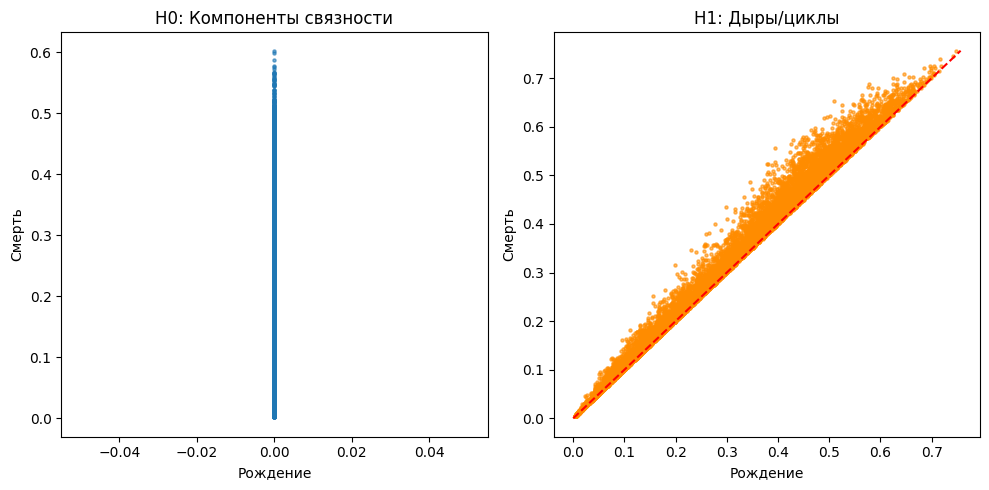

In [11]:
import numpy as np
import matplotlib.pyplot as plt

h0 = np.load('res_akk/h0_results_akk.npy')
h1 = np.load('res_akk/h1_results_akk.npy')


plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.scatter(h0[:, 0], h0[:, 1], s=5, alpha=0.6)
plt.plot([0, max(h0[:, 1])], [0, max(h0[:, 1])], 'r--')
plt.xlabel('Рождение')
plt.ylabel('Смерть')
plt.title('H0: Компоненты связности')

plt.subplot(1, 2, 2)
plt.scatter(h1[:, 0], h1[:, 1], s=5, alpha=0.6, c='darkorange')
plt.plot([0, max(h1[:, 1])], [0, max(h1[:, 1])], 'r--')
plt.xlabel('Рождение')
plt.ylabel('Смерть')
plt.title('H1: Дыры/циклы')

plt.tight_layout()
plt.savefig('persistence_diagrams.png', dpi=150)
plt.show()

In [15]:
#кол-во кластеров
# Количество значимых компонент (рождение близко к 0, смерть далеко)
significant_h0 = h0[h0[:, 1] - h0[:, 0] > np.percentile(h0[:, 1] - h0[:, 0], 75)]

print(f"Общее число компонент связности: {len(h0)}")
print(f"Число кластеров: {len(significant_h0)}")

Общее число компонент связности: 16396
Число филтров: 4099


In [16]:
# Бутстрап-анализ устойчивости топологии
def analyze_barcodes(barcodes):
    """Анализ баркодов: количество интервалов, максимальная персистентность"""
    persistence = barcodes[:, 1] - barcodes[:, 0]
    return len(barcodes), np.max(persistence), np.mean(persistence)

# Анализ оригинальных данных
n_h0, max_h0, mean_h0 = analyze_barcodes(h0)
n_h1, max_h1, mean_h1 = analyze_barcodes(h1)

print("=== ОРИГИНАЛЬНЫЕ ДАННЫЕ ===")
print(f"H0: {n_h0} компонент, макс. перс: {max_h0:.3f}")
print(f"H1: {n_h1} дыр, макс. перс: {max_h1:.3f}")
print(f"Соотношение дыры/компоненты: {n_h1/n_h0:.2f}")

=== ОРИГИНАЛЬНЫЕ ДАННЫЕ ===
H0: 16396 компонент, макс. перс: inf
H1: 12788 дыр, макс. перс: 0.161
Соотношение дыры/компоненты: 0.78
